# Month Data Aggregation

In [ ]:
import torch
from torch_geometric.data import HeteroData
import pandas as pd
import glob
import numpy as np
import gc
import pyarrow.parquet as pq

# Load and aggregate data with weights
def load_and_aggregate_all_files(file_pattern, batch_size=1000000):
    file_list = sorted(glob.glob(file_pattern))
    if not file_list:
        raise ValueError(f"No files found for pattern: {file_pattern}")
    
    print(f"Found {len(file_list)} files to process")
    df_full_agg = None
    
    for i, file in enumerate(file_list):
        day = int(file.split('_')[-1].replace('.parquet', '')[-2:])
        print(f"Processing file {i+1}/{len(file_list)} (day {day})")
        parquet_file = pq.ParquetFile(file)
        for batch in parquet_file.iter_batches(batch_size=batch_size):
            chunk = batch.to_pandas()
            chunk = chunk.dropna(subset=['PANELISTID', 'APPDESCRIPTION', 'FOREGROUNDDURATION'])
            df_agg = chunk.groupby(['PANELISTID', 'APPDESCRIPTION'])['FOREGROUNDDURATION'].sum().reset_index(name='weight')
            if df_full_agg is None:
                df_full_agg = df_agg
            else:
                df_full_agg = pd.concat([df_full_agg, df_agg]).groupby(['PANELISTID', 'APPDESCRIPTION'], as_index=False)['weight'].sum()
            print(f"Current aggregated shape: {df_full_agg.shape}")
            del chunk, df_agg
            gc.collect()
        print(f"Finished file {i+1}")
    return df_full_agg

# Load and save January data
try:
    df_jan_full = load_and_aggregate_all_files('data/2024/01/data_202401*.parquet')
    print(f"Full January aggregated shape: {df_jan_full.shape}")
    # Save aggregated January data to Parquet
    df_jan_full.to_parquet('jan_aggregated.parquet', index=False)
    print("Saved aggregated January data to 'jan_aggregated.parquet'")
except Exception as e:
    print(f"Error loading January data: {e}")
    raise

# Load and save February data
try:
    df_feb_full = load_and_aggregate_all_files('data/2024/02/data_202402*.parquet')
    print(f"Full February aggregated shape: {df_feb_full.shape}")
    # Save aggregated February data to Parquet
    df_feb_full.to_parquet('feb_aggregated.parquet', index=False)
    print("Saved aggregated February data to 'feb_aggregated.parquet'")
except Exception as e:
    print(f"Error loading February data: {e}")
    raise

# Build January graph with forward and reverse edges
data_jan = HeteroData()
unique_users_jan = df_jan_full['PANELISTID'].unique()
unique_apps_jan = df_jan_full['APPDESCRIPTION'].unique()
data_jan['user'].num_nodes = len(unique_users_jan)
data_jan['app'].num_nodes = len(unique_apps_jan)
user_mapping_jan = {user_id: idx for idx, user_id in enumerate(unique_users_jan)}
app_mapping_jan = {app_id: idx for idx, app_id in enumerate(unique_apps_jan)}
source_jan = df_jan_full['PANELISTID'].map(user_mapping_jan)
target_jan = df_jan_full['APPDESCRIPTION'].map(app_mapping_jan)
if source_jan.isnull().any() or target_jan.isnull().any():
    raise ValueError("NaN values in January edge indices")

edge_index_jan = torch.tensor([source_jan.values, target_jan.values], dtype=torch.long)
data_jan['user', 'uses', 'app'].edge_index = edge_index_jan
edge_index_jan_reverse = torch.tensor([target_jan.values, source_jan.values], dtype=torch.long)
data_jan['app', 'uses', 'user'].edge_index = edge_index_jan_reverse

print(f"Full Jan edge index shape (user -> app): {edge_index_jan.shape}")
print(f"Full Jan edge index shape (app -> user): {edge_index_jan_reverse.shape}")

# Save January graph
torch.save(data_jan, 'jan_graph.pt')
print("Saved January graph to 'jan_graph.pt'")

# Save user and app mappings for reference
mappings = {
    'user_mapping_jan': user_mapping_jan,
    'app_mapping_jan': app_mapping_jan
}
torch.save(mappings, 'jan_mappings.pt')
print("Saved January user and app mappings to 'jan_mappings.pt'")

# Memory cleanup
del df_jan_full, df_feb_full, data_jan, edge_index_jan, edge_index_jan_reverse
gc.collect()

Found 31 files to process
Processing file 1/31 (day 1)
Current aggregated shape: (224374, 3)
Current aggregated shape: (291273, 3)
Current aggregated shape: (331117, 3)
Current aggregated shape: (358778, 3)
Current aggregated shape: (379462, 3)
Current aggregated shape: (395802, 3)
Current aggregated shape: (399507, 3)
Finished file 1
Processing file 2/31 (day 2)
Current aggregated shape: (474164, 3)
Current aggregated shape: (508004, 3)
Current aggregated shape: (530380, 3)
Current aggregated shape: (546880, 3)
Current aggregated shape: (559719, 3)
Current aggregated shape: (569979, 3)
Current aggregated shape: (572847, 3)
Finished file 2
Processing file 3/31 (day 3)
Current aggregated shape: (621145, 3)
Current aggregated shape: (644233, 3)
Current aggregated shape: (659842, 3)
Current aggregated shape: (671408, 3)
Current aggregated shape: (680846, 3)
Current aggregated shape: (688385, 3)
Current aggregated shape: (691071, 3)
Finished file 3
Processing file 4/31 (day 4)
Current aggr

/var/folders/l5/sd0jnm712nvcm2c5_ycg3h8w0000gn/T/ipykernel_48404/1551626095.py:71: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:281.)
  edge_index_jan = torch.tensor([source_jan.values, target_jan.values], dtype=torch.long)


Full Jan edge index shape (user -> app): torch.Size([2, 2210089])
Full Jan edge index shape (app -> user): torch.Size([2, 2210089])
Saved January graph to 'jan_graph.pt'
Saved January user and app mappings to 'jan_mappings.pt'


0

: 

# Metapath2vec model training

Using device: mps
Loaded January data: (2210089, 3), February data: (2429195, 3)
January mappings: 34639 users, 74754 apps
January graph: users=34639, apps=74754
February graph: users=40001, apps=80277
Epoch 0, Loss: 1.7051
Epoch 10, Loss: 0.9064
Epoch 20, Loss: 0.9046
Epoch 30, Loss: 0.9025
Epoch 40, Loss: 0.9013
Average training loss: 0.9230
Model saved to metapath2vec_january.pth
January user embeddings shape: (34639, 64)
January app embeddings shape: (74754, 64)
Filtered to 14349 popular apps for similarity computation (January)
Filtered to 14959 popular apps for similarity computation (February)
Operator: hadamard, ROC-AUC: 0.9009, Precision: 0.9052, Recall: 0.8434, F1: 0.8732, Threshold: 0.3853
Operator: l1, ROC-AUC: 0.8963, Precision: 0.8934, Recall: 0.7697, F1: 0.8269, Threshold: 0.3483
Operator: l2, ROC-AUC: 0.8792, Precision: 0.9110, Recall: 0.7536, F1: 0.8248, Threshold: 0.3583
Operator: average, ROC-AUC: 0.9123, Precision: 0.8924, Recall: 0.7983, F1: 0.8427, Threshold: 0.44

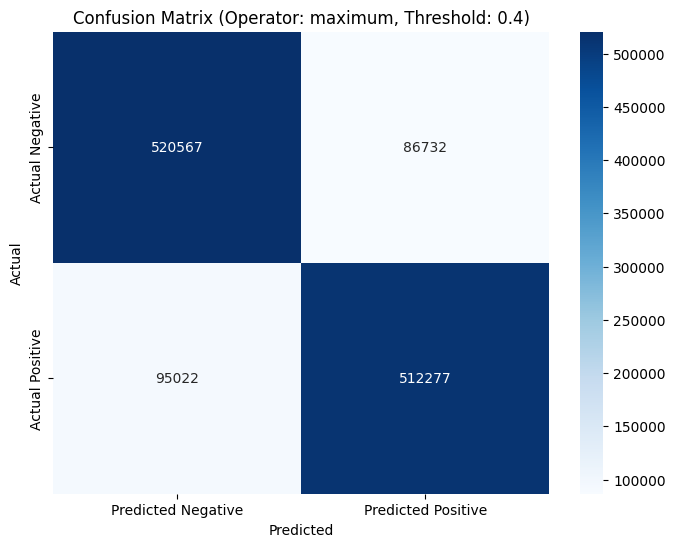


--- Analyzing cosine ---

Top 10 App-App Pairs by cosine_jan Similarity:
Chrome Browser  - Google Play: 0.0156
Google Play - Google Play services: 0.0156
Gmail - Google Play services: 0.0156
Facebook - Facebook Messenger: 0.0156
Google Search - YouTube: 0.0156
Chrome Browser  - Google Play services: 0.0156
Gmail - Google Play: 0.0156
Chrome Browser  - Gmail: 0.0156
Android System - Permission controller: 0.0156
Google Play services - Google Search: 0.0156

Validation of Top App Pairs with February Data:
Chrome Browser  - Google Play: Jaccard Similarity (User Overlap) = 0.8666
Google Play - Google Play services: Jaccard Similarity (User Overlap) = 0.8201
Gmail - Google Play services: Jaccard Similarity (User Overlap) = 0.7642
Facebook - Facebook Messenger: Jaccard Similarity (User Overlap) = 0.7909
Google Search - YouTube: Jaccard Similarity (User Overlap) = 0.7256
Chrome Browser  - Google Play services: Jaccard Similarity (User Overlap) = 0.7856
Gmail - Google Play: Jaccard Similarity

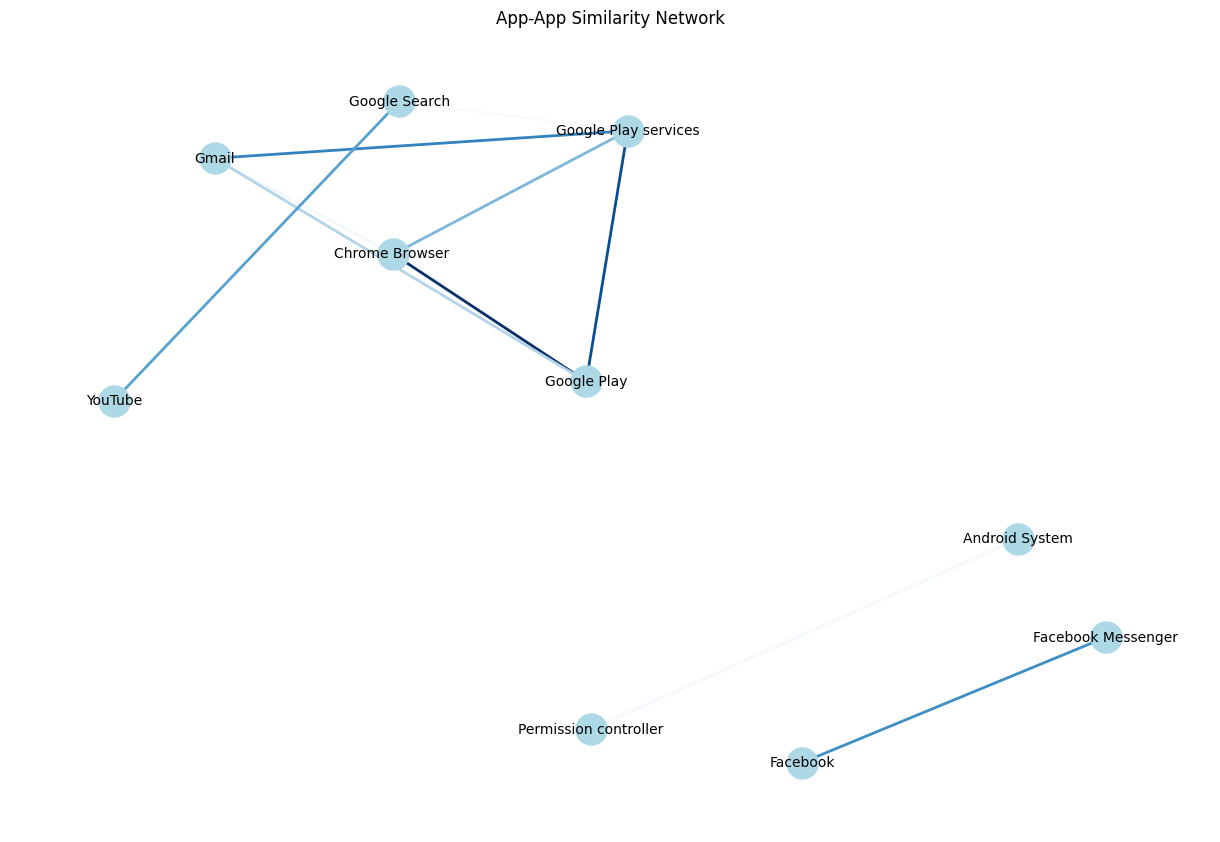


--- Analyzing l1 ---

Top 10 App-App Pairs by l1_jan Distance:
Calm Baby - WMKV 89.3 FM: 3.6186
Chrome Browser  - Google Play: 3.6750
Reef - WMKV 89.3 FM: 3.7181
Google Play services - Google Search: 3.9283
Controlador de permisos - Sistema Android: 4.0852
Cámara - Modos y rutinas: 4.1433
Match _ Sort 3D Puzzles - Rainbow Puzzles Sort The Colours: 4.1708
Appareil photo - ParamÃ¨tres: 4.1830
Jigsaw To Pictures - Tricky Letters Find Words: 4.2624
Sea Treasure - Tricky Letters Find Words: 4.2942

Validation of Top App Pairs with February Data:
Calm Baby - WMKV 89.3 FM: Jaccard Similarity (User Overlap) = 0.0000
Chrome Browser  - Google Play: Jaccard Similarity (User Overlap) = 0.8666
Reef - WMKV 89.3 FM: Jaccard Similarity (User Overlap) = 0.0000
Google Play services - Google Search: Jaccard Similarity (User Overlap) = 0.7477
Controlador de permisos - Sistema Android: Jaccard Similarity (User Overlap) = 0.6272
Cámara - Modos y rutinas: Jaccard Similarity (User Overlap) = 0.0889
Match _ S

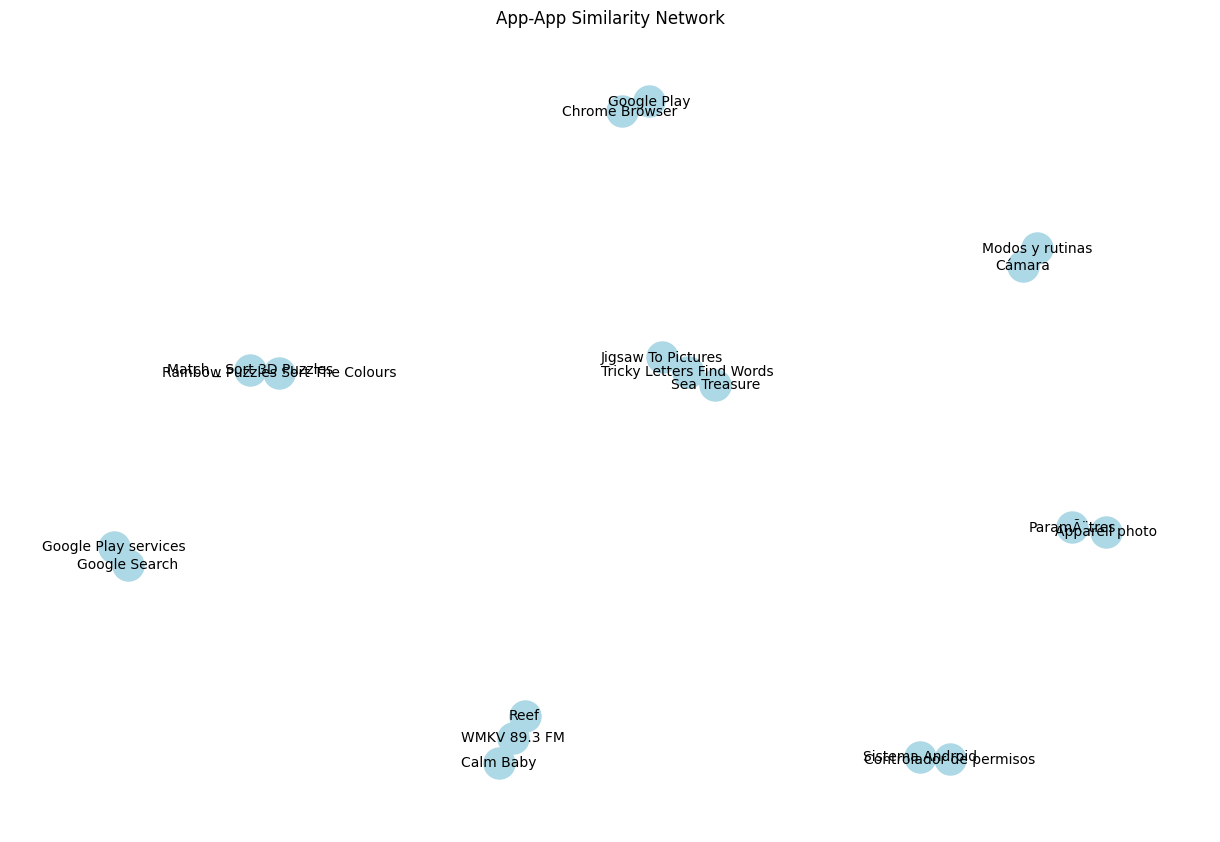


--- Analyzing exp_diff ---

Top 10 App-App Pairs by exp_diff_jan Similarity:
Calm Baby - WMKV 89.3 FM: 0.9461
Chrome Browser  - Google Play: 0.9458
Reef - WMKV 89.3 FM: 0.9448
Google Play services - Google Search: 0.9417
Controlador de permisos - Sistema Android: 0.9393
Cámara - Modos y rutinas: 0.9387
Match _ Sort 3D Puzzles - Rainbow Puzzles Sort The Colours: 0.9379
Appareil photo - ParamÃ¨tres: 0.9379
Facebook - Facebook Messenger: 0.9379
Jigsaw To Pictures - Tricky Letters Find Words: 0.9373

Validation of Top App Pairs with February Data:
Calm Baby - WMKV 89.3 FM: Jaccard Similarity (User Overlap) = 0.0000
Chrome Browser  - Google Play: Jaccard Similarity (User Overlap) = 0.8666
Reef - WMKV 89.3 FM: Jaccard Similarity (User Overlap) = 0.0000
Google Play services - Google Search: Jaccard Similarity (User Overlap) = 0.7477
Controlador de permisos - Sistema Android: Jaccard Similarity (User Overlap) = 0.6272
Cámara - Modos y rutinas: Jaccard Similarity (User Overlap) = 0.0889
Match 

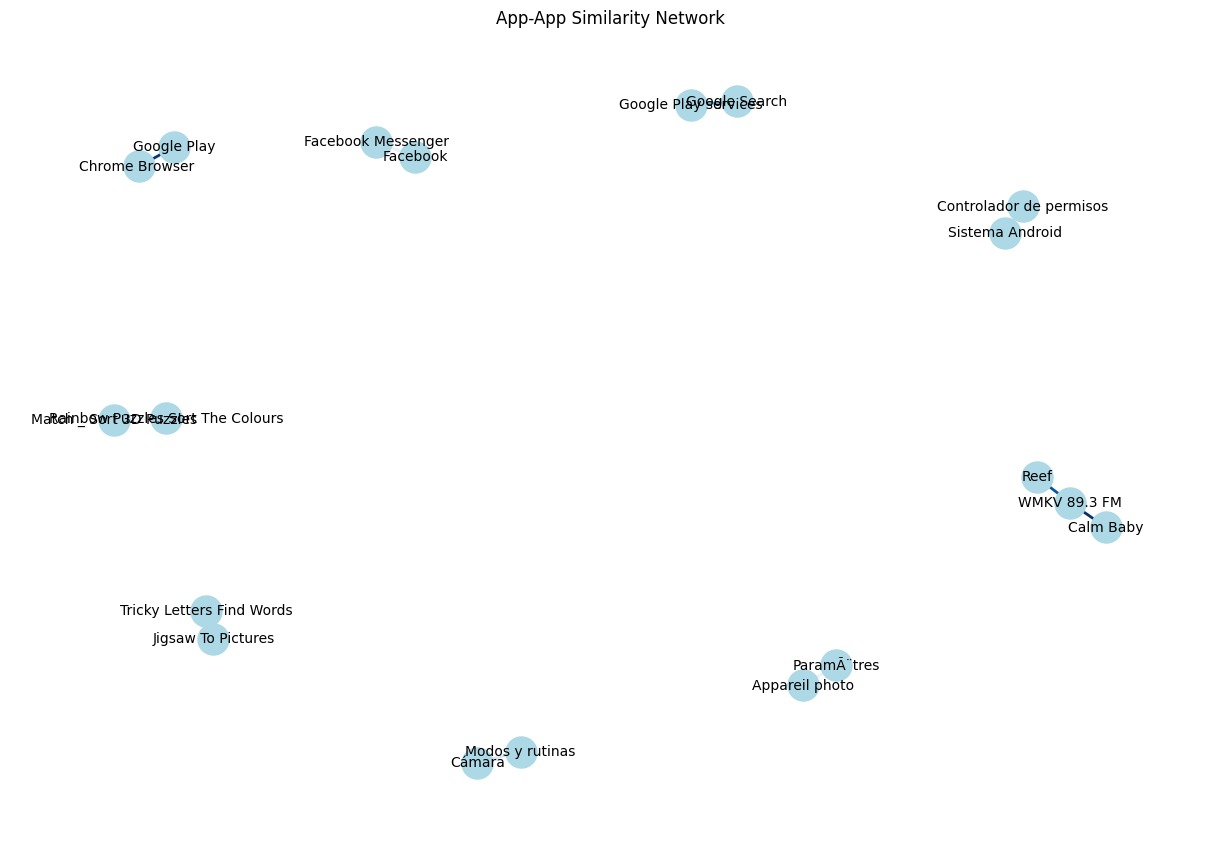

User - 2 clusters: Silhouette Score = 0.9746
User - 3 clusters: Silhouette Score = 0.0575
User - 4 clusters: Silhouette Score = 0.0540
User - 5 clusters: Silhouette Score = 0.0564
User - 6 clusters: Silhouette Score = 0.0205
User - 7 clusters: Silhouette Score = 0.0203
User - 8 clusters: Silhouette Score = 0.0223
User - 9 clusters: Silhouette Score = 0.0214
User - 10 clusters: Silhouette Score = 0.0228
Best number of User clusters: 2
App - 2 clusters: Silhouette Score = 0.9424
App - 3 clusters: Silhouette Score = 0.8988
App - 4 clusters: Silhouette Score = 0.4221
App - 5 clusters: Silhouette Score = 0.3645
App - 6 clusters: Silhouette Score = 0.3617
App - 7 clusters: Silhouette Score = 0.1951
App - 8 clusters: Silhouette Score = 0.0917
App - 9 clusters: Silhouette Score = 0.0914
App - 10 clusters: Silhouette Score = 0.0406
Best number of App clusters: 2


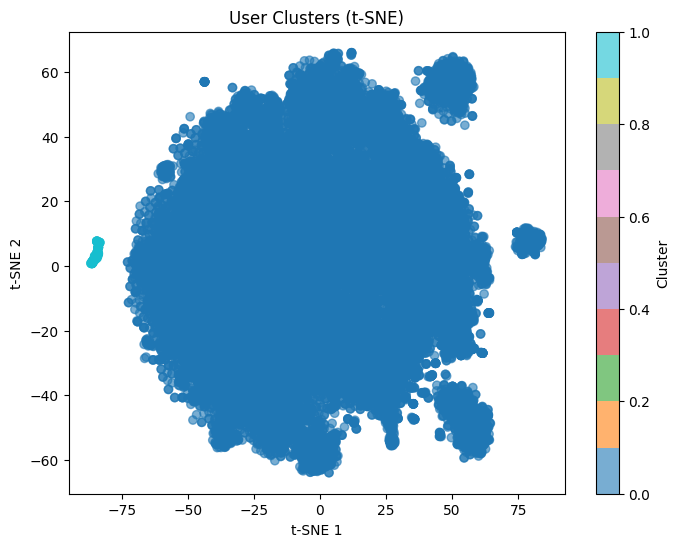

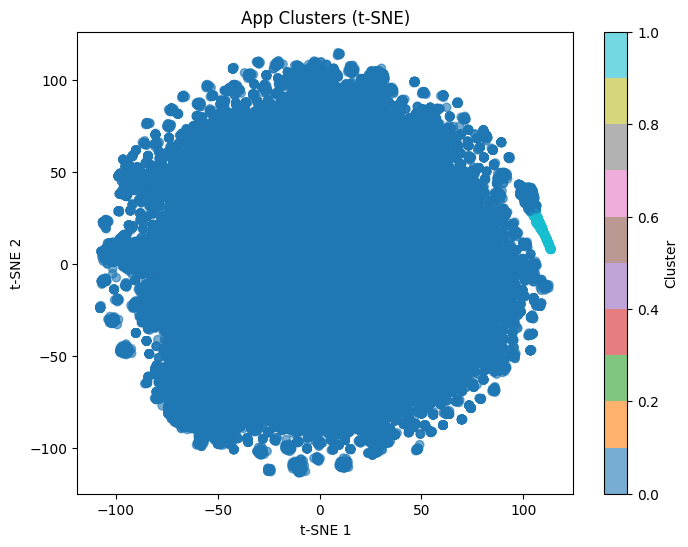


Computing similarity for Cluster 0 (74449 apps):


In [ ]:
import torch
from torch_geometric.data import HeteroData
from torch_geometric.nn import MetaPath2Vec
import pandas as pd
import numpy as np
import gc
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, roc_auc_score, precision_recall_curve, precision_score, recall_score, f1_score
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
import networkx as nx

# Set random seed for reproducibility
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed(42)

# Parameters
batch_size_train = 64
batch_size_predict = 500
embedding_dim = 64
epochs = 50
metapaths = [('app', 'uses', 'user'), ('user', 'uses', 'app')]
walk_length = 50
context_size = 5
walks_per_node = 50
num_negative_samples = 10
learning_rate = 0.005

top_k = 50
top_num = 50

# Device setup
device = torch.device('mps' if torch.backends.mps.is_available() else 'cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# Load data
def load_data():
    try:
        df_jan_full = pd.read_parquet('jan_aggregated.parquet')
        df_feb_full = pd.read_parquet('feb_aggregated.parquet')
        mappings = torch.load('jan_mappings.pt', weights_only=False)
        user_mapping_jan = mappings['user_mapping_jan']
        app_mapping_jan = mappings['app_mapping_jan']
        print(f"Loaded January data: {df_jan_full.shape}, February data: {df_feb_full.shape}")
        print(f"January mappings: {len(user_mapping_jan)} users, {len(app_mapping_jan)} apps")
        return df_jan_full, df_feb_full, user_mapping_jan, app_mapping_jan
    except Exception as e:
        print(f"Error loading data: {e}")
        raise

# Build January graph
def build_january_graph(df_jan_full):
    data_jan = HeteroData()
    unique_users_jan = df_jan_full['PANELISTID'].unique()
    unique_apps_jan = df_jan_full['APPDESCRIPTION'].unique()
    data_jan['user'].num_nodes = len(unique_users_jan)
    data_jan['app'].num_nodes = len(unique_apps_jan)
    user_mapping_jan = {user_id: idx for idx, user_id in enumerate(unique_users_jan)}
    app_mapping_jan = {app_id: idx for idx, app_id in enumerate(unique_apps_jan)}
    
    source_jan = df_jan_full['PANELISTID'].map(user_mapping_jan)
    target_jan = df_jan_full['APPDESCRIPTION'].map(app_mapping_jan)
    if source_jan.isnull().any() or target_jan.isnull().any():
        raise ValueError("NaN values in January edge indices")
    
    edge_indices = np.vstack([source_jan.values, target_jan.values])
    edge_index_jan = torch.tensor(edge_indices, dtype=torch.long)
    edge_indices_reverse = np.vstack([target_jan.values, source_jan.values])
    edge_index_jan_reverse = torch.tensor(edge_indices_reverse, dtype=torch.long)
    data_jan['user', 'uses', 'app'].edge_index = edge_index_jan
    data_jan['app', 'uses', 'user'].edge_index = edge_index_jan_reverse
    print(f"January graph: users={data_jan['user'].num_nodes}, apps={data_jan['app'].num_nodes}")
    return data_jan, user_mapping_jan, app_mapping_jan, unique_users_jan, unique_apps_jan

# Build February graph
def build_february_graph(df_feb_full):
    data_feb = HeteroData()
    unique_users_feb = df_feb_full['PANELISTID'].unique()
    unique_apps_feb = df_feb_full['APPDESCRIPTION'].unique()
    data_feb['user'].num_nodes = len(unique_users_feb)
    data_feb['app'].num_nodes = len(unique_apps_feb)
    user_mapping_feb = {user_id: idx for idx, user_id in enumerate(unique_users_feb)}
    app_mapping_feb = {app_id: idx for idx, app_id in enumerate(unique_apps_feb)}
    
    source_feb = df_feb_full['PANELISTID'].map(user_mapping_feb)
    target_feb = df_feb_full['APPDESCRIPTION'].map(app_mapping_feb)
    if source_feb.isnull().any() or target_feb.isnull().any():
        raise ValueError("NaN values in February edge indices")
    
    edge_indices = np.vstack([source_feb.values, target_feb.values])
    edge_index_feb = torch.tensor(edge_indices, dtype=torch.long)
    data_feb['user', 'uses', 'app'].edge_index = edge_index_feb
    print(f"February graph: users={data_feb['user'].num_nodes}, apps={data_feb['app'].num_nodes}")
    return data_feb, user_mapping_feb, app_mapping_feb, unique_users_feb, unique_apps_feb

# Train MetaPath2Vec
def train_metapath2vec(data, model, optimizer, epochs):
    model.train()
    total_loss = 0
    loader = model.loader(batch_size=batch_size_train, shuffle=True)
    for epoch in range(epochs):
        epoch_loss = 0
        for i, (pos_rw, neg_rw) in enumerate(loader):
            try:
                optimizer.zero_grad()
                pos_rw, neg_rw = pos_rw.to(device), neg_rw.to(device)
                loss = model.loss(pos_rw, neg_rw)
                loss.backward()
                optimizer.step()
                epoch_loss += loss.item()
                if i % 10 == 0:
                    if device.type == 'cuda':
                        torch.cuda.empty_cache()
                    elif device.type == 'mps':
                        torch.mps.empty_cache()
                    gc.collect()
            except RuntimeError as e:
                print(f"Epoch {epoch}, Batch {i}: Memory error - {e}")
                break
        avg_epoch_loss = epoch_loss / len(loader) if len(loader) > 0 else 0
        total_loss += avg_epoch_loss
        if epoch % 10 == 0:
            print(f"Epoch {epoch}, Loss: {avg_epoch_loss:.4f}")
        if device.type == 'cuda':
            torch.cuda.empty_cache()
        elif device.type == 'mps':
            torch.mps.empty_cache()
        gc.collect() 
    return total_loss / epochs if epochs > 0 else 0

# Initialize February embeddings
def initialize_feb_embeddings(unique_entities_feb, entity_mapping_jan, embeddings_jan, embedding_dim, method='mean'):
    embeddings_feb = np.zeros((len(unique_entities_feb), embedding_dim), dtype=np.float32)
    mean_embedding = np.mean(embeddings_jan, axis=0) if method == 'mean' else None
    for i, entity in enumerate(unique_entities_feb):
        if entity in entity_mapping_jan:
            embeddings_feb[i] = embeddings_jan[entity_mapping_jan[entity]]
        else:
            embeddings_feb[i] = mean_embedding if method == 'mean' else np.random.normal(0, 0.01, embedding_dim)
    return embeddings_feb

# Binary operators for edge features and app-app similarity
def hadamard(u, v): return u * v
def l1(u, v): return np.abs(u - v)
def l2(u, v): return (u - v) ** 2
def average(u, v): return (u + v) / 2
def cosine(u, v):
    norm_u = np.linalg.norm(u)
    norm_v = np.linalg.norm(v)
    norm_u = 1e-10 if norm_u == 0 else norm_u
    norm_v = 1e-10 if norm_v == 0 else norm_v
    return (u * v) / (norm_u * norm_v)
def weighted_sum(u, v, w1=0.6, w2=0.4): return w1 * u + w2 * v
def maximum(u, v): return np.maximum(u, v)
def minimum(u, v): return np.minimum(u, v)
def exp_diff(u, v): return np.exp(-np.abs(u - v))

# Compute edge features
def compute_edge_features(user_emb, app_emb, edge_indices, binary_op):
    user_indices, app_indices = edge_indices
    return np.array([binary_op(user_emb[u], app_emb[a]) for u, a in zip(user_indices, app_indices)], dtype=np.float32)

# Compute app-app similarity
def compute_app_app_similarity(app_embeddings, app_mapping, binary_op, op_name, df, top_k, is_distance=False):
    num_apps = app_embeddings.shape[0]
    app_ids = list(app_mapping.keys())
    
    scores = np.zeros((num_apps, num_apps), dtype=np.float32)
    for i in range(num_apps):
        for j in range(i + 1, num_apps):
            score_vec = binary_op(app_embeddings[i], app_embeddings[j])
            score = np.mean(score_vec) if not is_distance else np.sum(score_vec)
            scores[i, j] = score
            scores[j, i] = score
    
    indices = np.triu_indices(num_apps, k=1)
    scores_flat = scores[indices]
    top_indices = np.argsort(scores_flat)[::-1][:top_k] if not is_distance else np.argsort(scores_flat)[:top_k]
    top_pairs = [(indices[0][idx], indices[1][idx]) for idx in top_indices]
    
    top_pairs_with_scores = [
        (app_ids[i], app_ids[j], scores[i, j])
        for i, j in top_pairs
    ]
    
    print(f"\nTop {top_k} App-App Pairs by {op_name} {'Similarity' if not is_distance else 'Distance'}:")
    for app1, app2, score in top_pairs_with_scores:
        print(f"{app1} - {app2}: {score:.4f}")
    
    return top_pairs_with_scores

# Validate app-app similarity using February data
def validate_app_pairs(top_pairs, df_feb, app_mapping):
    print("\nValidation of Top App Pairs with February Data:")
    for app1, app2, score in top_pairs:
        app1_idx = app_mapping[app1]
        app2_idx = app_mapping[app2]
        users_app1 = set(df_feb[df_feb['APPDESCRIPTION'] == app1]['PANELISTID'].unique())
        users_app2 = set(df_feb[df_feb['APPDESCRIPTION'] == app2]['PANELISTID'].unique())
        common_users = len(users_app1.intersection(users_app2))
        total_users = len(users_app1.union(users_app2))
        jaccard = common_users / total_users if total_users > 0 else 0
        print(f"{app1} - {app2}: Jaccard Similarity (User Overlap) = {jaccard:.4f}")

# Compare app-app similarity across months
def compare_temporal_similarity(top_pairs_jan, top_pairs_feb):
    print("\nTemporal Consistency Analysis of App-App Similarity:")
    pairs_jan = {(app1, app2) for app1, app2, _ in top_pairs_jan}
    pairs_feb = {(app1, app2) for app1, app2, _ in top_pairs_feb}
    common_pairs = pairs_jan.intersection(pairs_feb)
    consistency_ratio = len(common_pairs) / len(pairs_jan) if len(pairs_jan) > 0 else 0
    print(f"Number of common app-app pairs between January and February: {len(common_pairs)}")
    print(f"Consistency ratio: {consistency_ratio:.4f}")
    for app1, app2 in common_pairs:
        score_jan = next(score for a1, a2, score in top_pairs_jan if (a1, a2) == (app1, app2))
        score_feb = next(score for a1, a2, score in top_pairs_feb if (a1, a2) == (app1, app2))
        print(f"{app1} - {app2}: January Score = {score_jan:.4f}, February Score = {score_feb:.4f}")

# Compute app-app similarity within clusters
def compute_similarity_within_clusters(app_embeddings, app_mapping, app_clusters, n_clusters, binary_op, op_name, df, top_k=5, is_distance=False):
    app_ids = list(app_mapping.keys())
    for cluster_id in range(n_clusters):
        cluster_indices = np.where(app_clusters == cluster_id)[0]
        if len(cluster_indices) < 2:
            print(f"Cluster {cluster_id} has fewer than 2 apps, skipping.")
            continue
        cluster_embeddings = app_embeddings[cluster_indices]
        cluster_mapping = {app_ids[idx]: i for i, idx in enumerate(cluster_indices)}
        print(f"\nComputing similarity for Cluster {cluster_id} ({len(cluster_indices)} apps):")
        compute_app_app_similarity(cluster_embeddings, cluster_mapping, binary_op, f"{op_name}_cluster_{cluster_id}", df, top_k=top_k, is_distance=is_distance)

# Visualize app-app similarity network
def visualize_app_similarity_network(top_pairs, filename="app_similarity_network.png"):
    G = nx.Graph()
    for app1, app2, score in top_pairs:
        G.add_edge(app1, app2, weight=score)
    
    plt.figure(figsize=(12, 8))
    pos = nx.spring_layout(G)
    edges = G.edges(data=True)
    weights = [edge[2]['weight'] for edge in edges]
    nx.draw(G, pos, with_labels=True, node_color='lightblue', node_size=500, font_size=10, edge_color=weights, edge_cmap=plt.cm.Blues, width=2)
    plt.title("App-App Similarity Network")
    plt.show()
    plt.close()

# Train and evaluate classifier
def train_classifier(X, y, X_val, y_val, binary_op_name, scaler=None):
    if scaler:
        X_scaled = scaler.fit_transform(X)
        X_val_scaled = scaler.transform(X_val)
    else:
        X_scaled, X_val_scaled = X, X_val
    
    clf = LogisticRegression(max_iter=1000, class_weight='balanced')
    clf.fit(X_scaled, y)
    
    pred_probs = clf.predict_proba(X_val_scaled)[:, 1]
    roc_auc = roc_auc_score(y_val, pred_probs)
    
    prec, rec, thresholds = precision_recall_curve(y_val, pred_probs)
    f1_scores = 2 * (prec * rec) / (prec + rec + 1e-10)
    best_threshold = thresholds[np.argmax(f1_scores)]
    pred_labels = (pred_probs > best_threshold).astype(np.int8)
    
    precision = precision_score(y_val, pred_labels)
    recall = recall_score(y_val, pred_labels)
    f1 = f1_score(y_val, pred_labels)
    
    return clf, scaler, roc_auc, precision, recall, f1, best_threshold, pred_labels, pred_probs

# Cluster and evaluate
def cluster_and_evaluate(embeddings, name, max_clusters=10):
    silhouette_scores = []
    cluster_labels = []
    for n_clusters in range(2, max_clusters + 1):
        kmeans = KMeans(n_clusters=n_clusters, random_state=42)
        labels = kmeans.fit_predict(embeddings)
        score = silhouette_score(embeddings, labels)
        silhouette_scores.append(score)
        cluster_labels.append(labels)
        print(f"{name} - {n_clusters} clusters: Silhouette Score = {score:.4f}")
    
    best_n_clusters = np.argmax(silhouette_scores) + 2
    best_labels = cluster_labels[best_n_clusters - 2]
    print(f"Best number of {name} clusters: {best_n_clusters}")
    return best_labels, best_n_clusters

# Visualize clusters
def visualize_clusters(embeddings, labels, name):
    tsne = TSNE(n_components=2, random_state=42, n_jobs=-1)
    embeddings_2d = tsne.fit_transform(embeddings)
    
    plt.figure(figsize=(8, 6))
    scatter = plt.scatter(embeddings_2d[:, 0], embeddings_2d[:, 1], c=labels, cmap='tab10', alpha=0.6)
    plt.title(f'{name} Clusters (t-SNE)')
    plt.colorbar(scatter, label='Cluster')
    plt.xlabel('t-SNE 1')
    plt.ylabel('t-SNE 2')
    plt.show()
    plt.close()

# Recommend apps
def recommend_apps(user_id, user_embeddings, app_embeddings, user_mapping, app_mapping, user_clusters, df_feb, top_n=5):
    if user_id not in user_mapping:
        print(f"User {user_id} not found in January data.")
        return [], 0.0
    
    user_idx = user_mapping[user_id]
    user_emb = user_embeddings[user_idx]
    user_cluster = user_clusters[user_idx]
    
    cluster_users = np.where(user_clusters == user_cluster)[0]
    cluster_user_ids = [list(user_mapping.keys())[list(user_mapping.values()).index(idx)] for idx in cluster_users]
    cluster_apps = df_feb[df_feb['PANELISTID'].isin(cluster_user_ids)]['APPDESCRIPTION'].value_counts().head(top_n).index
    
    user_norm = np.linalg.norm(user_emb)
    app_norms = np.linalg.norm(app_embeddings, axis=1)
    app_norms[app_norms == 0] = 1e-10
    similarities = np.dot(app_embeddings, user_emb) / (user_norm * app_norms)
    
    app_indices = [app_mapping[app] for app in cluster_apps if app in app_mapping]
    similarities[app_indices] *= 1.2
    
    top_indices = np.argsort(similarities)[-top_n:][::-1]
    recommended_apps = [list(app_mapping.keys())[list(app_mapping.values()).index(idx)] for idx in top_indices]
    
    user_feb_apps = df_feb[df_feb['PANELISTID'] == user_id]['APPDESCRIPTION'].unique()
    hits = sum(app in user_feb_apps for app in recommended_apps)
    hit_rate = hits / top_n if top_n > 0 else 0
    return recommended_apps, hit_rate

# Analyze popular apps
def analyze_popular_apps(df_feb):
    duration = df_feb.groupby('APPDESCRIPTION')['weight'].sum()
    user_count = df_feb.groupby('APPDESCRIPTION')['PANELISTID'].nunique()
    duration_norm = (duration - duration.min()) / (duration.max() - duration.min() + 1e-10)
    user_count_norm = (user_count - user_count.min()) / (user_count.max() - user_count.min() + 1e-10)
    popularity_score = 0.7 * duration_norm + 0.3 * user_count_norm
    
    top_apps = popularity_score.sort_values(ascending=False).head(top_num).reset_index()
    top_apps.columns = ['APPDESCRIPTION', 'PopularityScore']
    
    plt.figure(figsize=(10, 6))
    plt.barh(top_apps['APPDESCRIPTION'], top_apps['PopularityScore'], color='skyblue')
    plt.title('Top Most Popular Apps (Composite Score)')
    plt.xlabel('Popularity Score')
    plt.ylabel('App Description')
    plt.tight_layout()
    plt.show()
    plt.close()
    
    return top_apps

# Main workflow
def main():
    if device.type == 'cuda':
        torch.cuda.empty_cache()
    elif device.type == 'mps':
        torch.mps.empty_cache()
    gc.collect()

    df_jan_full, df_feb_full, user_mapping_jan, app_mapping_jan = load_data()
    
    data_jan, user_mapping_jan, app_mapping_jan, unique_users_jan, unique_apps_jan = build_january_graph(df_jan_full)
    data_feb, user_mapping_feb, app_mapping_feb, unique_users_feb, unique_apps_feb = build_february_graph(df_feb_full)
    
    try:
        data_jan = data_jan.to(device)
        model = MetaPath2Vec(
            edge_index_dict=data_jan.edge_index_dict,
            embedding_dim=embedding_dim,
            metapath=metapaths,
            walk_length=walk_length,
            context_size=context_size,
            walks_per_node=walks_per_node,
            num_negative_samples=num_negative_samples
        ).to(device)
    except RuntimeError as e:
        print(f"Failed to allocate to {device}: {e}. Falling back to CPU.")
        data_jan = data_jan.to('cpu')
        model = MetaPath2Vec(
            edge_index_dict=data_jan.edge_index_dict,
            embedding_dim=embedding_dim,
            metapath=metapaths,
            walk_length=walk_length,
            context_size=context_size,
            walks_per_node=walks_per_node,
            num_negative_samples=num_negative_samples
        ).to('cpu')
    
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    avg_loss = train_metapath2vec(data_jan, model, optimizer, epochs)
    print(f"Average training loss: {avg_loss:.4f}")
    
    model_path = "metapath2vec_january.pth"
    torch.save({
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'avg_loss': avg_loss,
        'embedding_dim': embedding_dim,
        'metapaths': metapaths,
        'user_mapping': user_mapping_jan,
        'app_mapping': app_mapping_jan
    }, model_path)
    print(f"Model saved to {model_path}")
    
    user_embeddings_jan = model('user').detach().cpu().numpy()
    app_embeddings_jan = model('app').detach().cpu().numpy()
    print(f"January user embeddings shape: {user_embeddings_jan.shape}")
    print(f"January app embeddings shape: {app_embeddings_jan.shape}")
    
    app_usage = df_jan_full.groupby('APPDESCRIPTION')['weight'].sum()
    app_user_count = df_jan_full.groupby('APPDESCRIPTION')['PANELISTID'].nunique()
    min_duration = app_usage.quantile(0.1, interpolation='nearest')
    min_users = 5
    popular_apps = app_usage[(app_usage > min_duration) & (app_user_count > min_users)].index
    app_indices = [app_mapping_jan[app] for app in popular_apps if app in app_mapping_jan]
    filtered_app_embeddings_jan = app_embeddings_jan[app_indices]
    filtered_app_mapping_jan = {app: idx for idx, app in enumerate(popular_apps)}
    print(f"Filtered to {len(popular_apps)} popular apps for similarity computation (January)")
    
    user_embeddings_feb = initialize_feb_embeddings(unique_users_feb, user_mapping_jan, user_embeddings_jan, embedding_dim, method='mean')
    app_embeddings_feb = initialize_feb_embeddings(unique_apps_feb, app_mapping_jan, app_embeddings_jan, embedding_dim, method='mean')
    
    app_usage_feb = df_feb_full.groupby('APPDESCRIPTION')['weight'].sum()
    app_user_count_feb = df_feb_full.groupby('APPDESCRIPTION')['PANELISTID'].nunique()
    min_duration_feb = app_usage_feb.quantile(0.1,interpolation='nearest')
    popular_apps_feb = app_usage_feb[(app_usage_feb > min_duration_feb) & (app_user_count_feb > min_users)].index
    app_indices_feb = [app_mapping_feb[app] for app in popular_apps_feb if app in app_mapping_feb]
    filtered_app_embeddings_feb = app_embeddings_feb[app_indices_feb]
    filtered_app_mapping_feb = {app: idx for idx, app in enumerate(popular_apps_feb)}
    print(f"Filtered to {len(popular_apps_feb)} popular apps for similarity computation (February)")

    # Link prediction with classifier
    true_edge_indices = data_feb['user', 'uses', 'app'].edge_index.cpu().numpy()
    true_indices_train, true_indices_val = train_test_split(np.arange(true_edge_indices.shape[1]), train_size=0.75, random_state=42)
    
    similarity = user_embeddings_feb @ app_embeddings_feb.T
    neg_indices = np.where(similarity > np.percentile(similarity, 90))
    neg_indices = np.array([neg_indices[0][:len(true_edge_indices[0])], neg_indices[1][:len(true_edge_indices[0])]])
    neg_indices_train, neg_indices_val = train_test_split(np.arange(neg_indices.shape[1]), train_size=0.75, random_state=42)
    
    binary_operators = {
        'hadamard': hadamard,
        'l1': l1,
        'l2': l2,
        'average': average,
        'cosine': cosine,
        'weighted_sum': weighted_sum,
        'maximum': maximum,
        'minimum': minimum,
        'exp_diff': exp_diff
    }
    
    best_clf, best_scaler, best_op, best_score, best_threshold, best_cm = None, None, None, 0, 0.5, None
    for op_name, op in binary_operators.items():
        true_features_train = compute_edge_features(user_embeddings_feb, app_embeddings_feb, [true_edge_indices[0][true_indices_train], true_edge_indices[1][true_indices_train]], op)
        neg_features_train = compute_edge_features(user_embeddings_feb, app_embeddings_feb, [neg_indices[0][neg_indices_train], neg_indices[1][neg_indices_train]], op)
        true_features_val = compute_edge_features(user_embeddings_feb, app_embeddings_feb, [true_edge_indices[0][true_indices_val], true_edge_indices[1][true_indices_val]], op)
        neg_features_val = compute_edge_features(user_embeddings_feb, app_embeddings_feb, [neg_indices[0][neg_indices_val], neg_indices[1][neg_indices_val]], op)
        
        X_train = np.vstack([true_features_train, neg_features_train])
        y_train = np.concatenate([np.ones(len(true_features_train)), np.zeros(len(neg_features_train))])
        X_val = np.vstack([true_features_val, neg_features_val])
        y_val = np.concatenate([np.ones(len(true_features_val)), np.zeros(len(neg_features_val))])
        
        scaler = StandardScaler()
        clf, scaler, roc_auc, precision, recall, f1, thresh, pred_labels, pred_probs = train_classifier(X_train, y_train, X_val, y_val, op_name, scaler)
        cm = confusion_matrix(y_val, pred_labels)
        print(f"Operator: {op_name}, ROC-AUC: {roc_auc:.4f}, Precision: {precision:.4f}, Recall: {recall:.4f}, F1: {f1:.4f}, Threshold: {thresh:.4f}")
        
        if roc_auc > best_score:
            best_clf, best_scaler, best_op, best_score, best_threshold, best_cm = clf, scaler, op, roc_auc, thresh, cm
    
    plt.figure(figsize=(8, 6))
    sns.heatmap(best_cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Predicted Negative', 'Predicted Positive'], yticklabels=['Actual Negative', 'Actual Positive'])
    plt.title(f'Confusion Matrix (Operator: {best_op.__name__}, Threshold: {best_threshold:.1f})')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()
    
    similarity_ops = [
        ('cosine', cosine, False),
        ('l1', l1, True),
        ('exp_diff', exp_diff, False)
    ]
    
    # Temporal consistency analysis
    for op_name, op, is_distance in similarity_ops:
        print(f"\n--- Analyzing {op_name} ---")
        top_pairs_jan = compute_app_app_similarity(filtered_app_embeddings_jan, filtered_app_mapping_jan, op, f"{op_name}_jan", df_jan_full, top_k=10, is_distance=is_distance)
        validate_app_pairs(top_pairs_jan, df_feb_full, filtered_app_mapping_jan)
        top_pairs_feb = compute_app_app_similarity(filtered_app_embeddings_feb, filtered_app_mapping_feb, op, f"{op_name}_feb", df_feb_full, top_k=10, is_distance=is_distance)
        compare_temporal_similarity(top_pairs_jan, top_pairs_feb)
        visualize_app_similarity_network(top_pairs_jan, f"app_similarity_network_{op_name}_jan.png")
    
    # Clustering
    user_clusters, user_n_clusters = cluster_and_evaluate(user_embeddings_jan, "User")
    app_clusters, app_n_clusters = cluster_and_evaluate(app_embeddings_jan, "App")
    visualize_clusters(user_embeddings_jan, user_clusters, "User")
    visualize_clusters(app_embeddings_jan, app_clusters, "App")
    
    # Cluster-based similarity
    for op_name, op, is_distance in similarity_ops:
        compute_similarity_within_clusters(app_embeddings_jan, app_mapping_jan, app_clusters, app_n_clusters, op, op_name, df_jan_full, top_k=5, is_distance=is_distance)
    
    sample_user_id = unique_users_jan[0]
    recommended_apps, hit_rate = recommend_apps(sample_user_id, user_embeddings_jan, app_embeddings_jan, user_mapping_jan, app_mapping_jan, user_clusters, df_feb_full)
    print(f"\nRecommended apps for user {sample_user_id}: {recommended_apps}")
    print(f"Hit rate: {hit_rate:.4f}")
    
    top_apps = analyze_popular_apps(df_feb_full)
    print("\nTop Most Popular Apps (Composite Score):")
    print(top_apps)

if __name__ == "__main__":
    main()

# Similarity Analysis

Using device: mps
Loaded January data: (2210089, 3), February data: (2429195, 3)
January mappings: 34639 users, 74754 apps
January graph: users=34639, apps=74754
February graph: users=40001, apps=80277
Loaded pre-trained model from metapath2vec_january.pth
January user embeddings shape: (34639, 64)
January app embeddings shape: (74754, 64)
Filtered to 14349 popular apps for similarity computation (January)
Filtered to 14959 popular apps for similarity computation (February)
Operator: hadamard, ROC-AUC: 0.9009, Precision: 0.9052, Recall: 0.8434, F1: 0.8732, Threshold: 0.3853
Operator: l1, ROC-AUC: 0.8963, Precision: 0.8934, Recall: 0.7697, F1: 0.8269, Threshold: 0.3483
Operator: l2, ROC-AUC: 0.8792, Precision: 0.9110, Recall: 0.7536, F1: 0.8248, Threshold: 0.3583
Operator: average, ROC-AUC: 0.9123, Precision: 0.8924, Recall: 0.7983, F1: 0.8427, Threshold: 0.4490
Operator: cosine, ROC-AUC: 0.8656, Precision: 0.8478, Recall: 0.7845, F1: 0.8149, Threshold: 0.5399
Operator: weighted_sum, RO

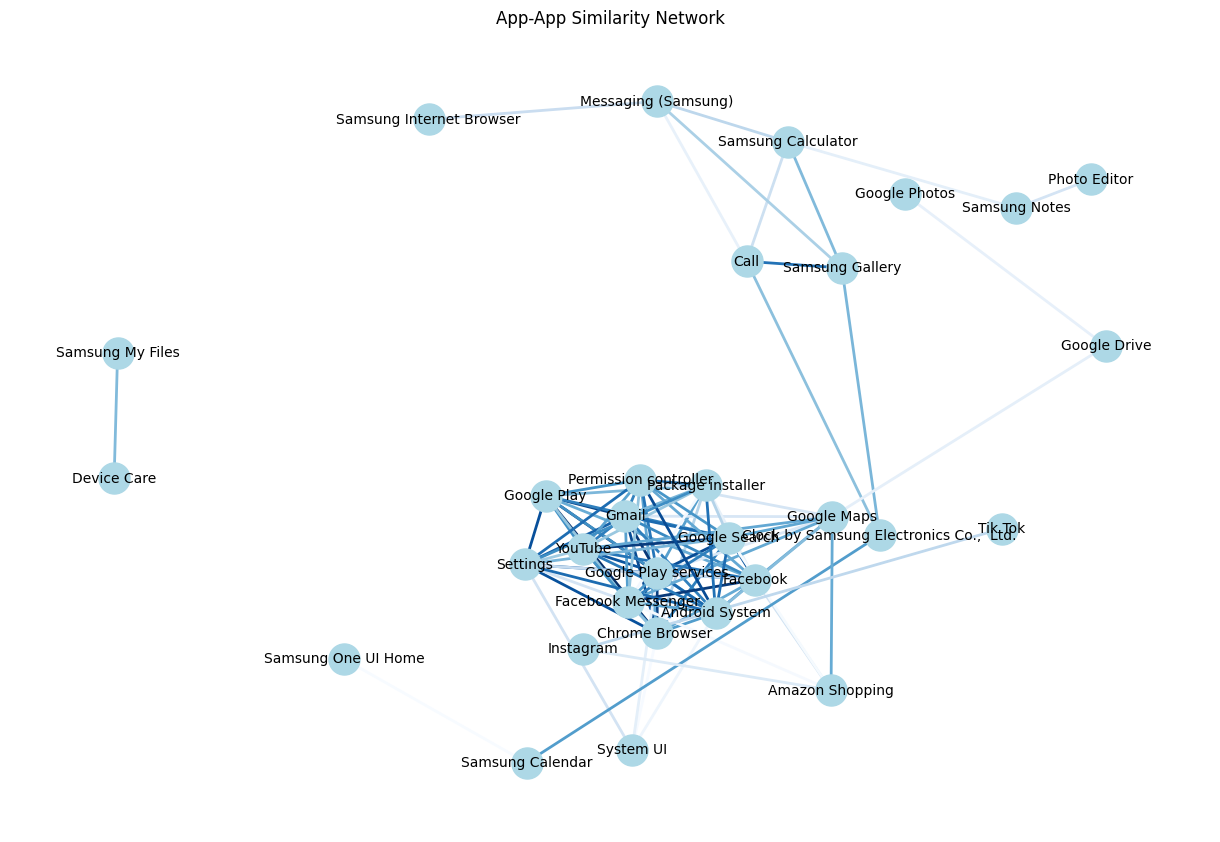

User - 2 clusters: Silhouette Score = 0.9746
User - 3 clusters: Silhouette Score = 0.0575
User - 4 clusters: Silhouette Score = 0.0540
User - 5 clusters: Silhouette Score = 0.0564
User - 6 clusters: Silhouette Score = 0.0205
User - 7 clusters: Silhouette Score = 0.0203
User - 8 clusters: Silhouette Score = 0.0223
User - 9 clusters: Silhouette Score = 0.0214
User - 10 clusters: Silhouette Score = 0.0228
Best number of User clusters: 2
App - 2 clusters: Silhouette Score = 0.9424
App - 3 clusters: Silhouette Score = 0.8988
App - 4 clusters: Silhouette Score = 0.4221
App - 5 clusters: Silhouette Score = 0.3645
App - 6 clusters: Silhouette Score = 0.3617
App - 7 clusters: Silhouette Score = 0.1951
App - 8 clusters: Silhouette Score = 0.0917
App - 9 clusters: Silhouette Score = 0.0914
App - 10 clusters: Silhouette Score = 0.0406
Best number of App clusters: 2


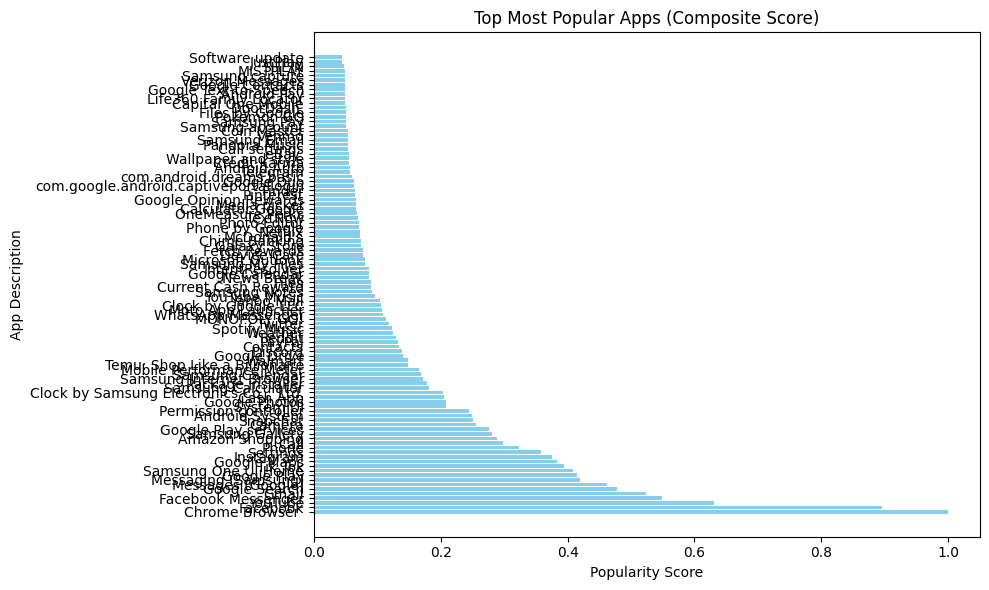


Top Most Popular Apps (Composite Score):
        APPDESCRIPTION  PopularityScore
0      Chrome Browser          1.000000
1             Facebook         0.894768
2              YouTube         0.631338
3   Facebook Messenger         0.548109
4                Gmail         0.523248
..                 ...              ...
95     Samsung capture         0.048966
96            MISTPLAY         0.048945
97               SHEIN         0.048202
98            JustPlay         0.045175
99     Software update         0.045024

[100 rows x 2 columns]

Top 5 App Pairs (Popularity Score 0.2-0.5):
Google Play - Google Play services: Similarity = 0.0156
Android System - Permission controller: Similarity = 0.0156
Google Search - Google Play services: Similarity = 0.0156
Google Play - Settings: Similarity = 0.0156
Settings - Google Play services: Similarity = 0.0156

Predicting switching for user GWSPanel0000E427A0144EEC with pair: Google Play - Google Play services
User GWSPanel0000E427A0144EEC did no

In [1]:
import torch
from torch_geometric.data import HeteroData
from torch_geometric.nn import MetaPath2Vec
import pandas as pd
import numpy as np
import gc
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, precision_recall_curve, precision_score, recall_score, f1_score
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.model_selection import train_test_split
import networkx as nx
import plotly.graph_objects as go
import matplotlib.pyplot as plt

# Set random seed for reproducibility
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed(42)

# Parameters
batch_size_train = 64
batch_size_predict = 500
embedding_dim = 64
epochs = 50
metapaths = [('app', 'uses', 'user'), ('user', 'uses', 'app')]
walk_length = 50
context_size = 5
walks_per_node = 50
num_negative_samples = 10
learning_rate = 0.005

top_k = 100
top_num = 100

# Device setup
device = torch.device('mps' if torch.backends.mps.is_available() else 'cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# Load data
def load_data():
    try:
        df_jan_full = pd.read_parquet('jan_aggregated.parquet')
        df_feb_full = pd.read_parquet('feb_aggregated.parquet')
        mappings = torch.load('jan_mappings.pt', weights_only=False)
        user_mapping_jan = mappings['user_mapping_jan']
        app_mapping_jan = mappings['app_mapping_jan']
        print(f"Loaded January data: {df_jan_full.shape}, February data: {df_feb_full.shape}")
        print(f"January mappings: {len(user_mapping_jan)} users, {len(app_mapping_jan)} apps")
        return df_jan_full, df_feb_full, user_mapping_jan, app_mapping_jan
    except Exception as e:
        print(f"Error loading data: {e}")
        raise

# Build January graph
def build_january_graph(df_jan_full):
    data_jan = HeteroData()
    unique_users_jan = df_jan_full['PANELISTID'].unique()
    unique_apps_jan = df_jan_full['APPDESCRIPTION'].unique()
    data_jan['user'].num_nodes = len(unique_users_jan)
    data_jan['app'].num_nodes = len(unique_apps_jan)
    user_mapping_jan = {user_id: idx for idx, user_id in enumerate(unique_users_jan)}
    app_mapping_jan = {app_id: idx for idx, app_id in enumerate(unique_apps_jan)}
    
    source_jan = df_jan_full['PANELISTID'].map(user_mapping_jan)
    target_jan = df_jan_full['APPDESCRIPTION'].map(app_mapping_jan)
    if source_jan.isnull().any() or target_jan.isnull().any():
        raise ValueError("NaN values in January edge indices")
    
    edge_indices = np.vstack([source_jan.values, target_jan.values])
    edge_index_jan = torch.tensor(edge_indices, dtype=torch.long)
    edge_indices_reverse = np.vstack([target_jan.values, source_jan.values])
    edge_index_jan_reverse = torch.tensor(edge_indices_reverse, dtype=torch.long)
    data_jan['user', 'uses', 'app'].edge_index = edge_index_jan
    data_jan['app', 'uses', 'user'].edge_index = edge_index_jan_reverse
    print(f"January graph: users={data_jan['user'].num_nodes}, apps={data_jan['app'].num_nodes}")
    return data_jan, user_mapping_jan, app_mapping_jan, unique_users_jan, unique_apps_jan

# Build February graph
def build_february_graph(df_feb_full):
    data_feb = HeteroData()
    unique_users_feb = df_feb_full['PANELISTID'].unique()
    unique_apps_feb = df_feb_full['APPDESCRIPTION'].unique()
    data_feb['user'].num_nodes = len(unique_users_feb)
    data_feb['app'].num_nodes = len(unique_apps_feb)
    user_mapping_feb = {user_id: idx for idx, user_id in enumerate(unique_users_feb)}
    app_mapping_feb = {app_id: idx for idx, app_id in enumerate(unique_apps_feb)}
    
    source_feb = df_feb_full['PANELISTID'].map(user_mapping_feb)
    target_feb = df_feb_full['APPDESCRIPTION'].map(app_mapping_feb)
    if source_feb.isnull().any() or target_feb.isnull().any():
        raise ValueError("NaN values in February edge indices")
    
    edge_indices = np.vstack([source_feb.values, target_feb.values])
    edge_index_feb = torch.tensor(edge_indices, dtype=torch.long)
    data_feb['user', 'uses', 'app'].edge_index = edge_index_feb
    print(f"February graph: users={data_feb['user'].num_nodes}, apps={data_feb['app'].num_nodes}")
    return data_feb, user_mapping_feb, app_mapping_feb, unique_users_feb, unique_apps_feb

# Initialize February embeddings
def initialize_feb_embeddings(unique_entities_feb, entity_mapping_jan, embeddings_jan, embedding_dim, method='mean'):
    embeddings_feb = np.zeros((len(unique_entities_feb), embedding_dim), dtype=np.float32)
    mean_embedding = np.mean(embeddings_jan, axis=0) if method == 'mean' else None
    for i, entity in enumerate(unique_entities_feb):
        if entity in entity_mapping_jan:
            embeddings_feb[i] = embeddings_jan[entity_mapping_jan[entity]]
        else:
            embeddings_feb[i] = mean_embedding if method == 'mean' else np.random.normal(0, 0.01, embedding_dim)
    return embeddings_feb

# Binary operators for edge features and app-app similarity
def hadamard(u, v): return u * v
def l1(u, v): return np.abs(u - v)
def l2(u, v): return (u - v) ** 2
def average(u, v): return (u + v) / 2
def cosine(u, v):
    norm_u = np.linalg.norm(u)
    norm_v = np.linalg.norm(v)
    norm_u = 1e-10 if norm_u == 0 else norm_u
    norm_v = 1e-10 if norm_v == 0 else norm_v
    return (u * v) / (norm_u * norm_v)
def weighted_sum(u, v, w1=0.6, w2=0.4): return w1 * u + w2 * v
def maximum(u, v): return np.maximum(u, v)
def minimum(u, v): return np.minimum(u, v)
def exp_diff(u, v): return np.exp(-np.abs(u - v))

# Compute edge features
def compute_edge_features(user_emb, app_emb, edge_indices, binary_op):
    user_indices, app_indices = edge_indices
    return np.array([binary_op(user_emb[u], app_emb[a]) for u, a in zip(user_indices, app_indices)], dtype=np.float32)

#Compute app-app similarity
def compute_app_app_similarity(app_embeddings, app_mapping, binary_op, op_name, df, top_k, is_distance=False):
    num_apps = app_embeddings.shape[0]
    app_ids = list(app_mapping.keys())
    
    scores = np.zeros((num_apps, num_apps), dtype=np.float32)
    for i in range(num_apps):
        for j in range(i + 1, num_apps):
            score_vec = binary_op(app_embeddings[i], app_embeddings[j])
            score = np.mean(score_vec) if not is_distance else np.sum(score_vec)
            scores[i, j] = score
            scores[j, i] = score
    
    indices = np.triu_indices(num_apps, k=1)
    scores_flat = scores[indices]
    top_indices = np.argsort(scores_flat)[::-1][:top_k] if not is_distance else np.argsort(scores_flat)[:top_k]
    top_pairs = [(indices[0][idx], indices[1][idx]) for idx in top_indices]
    
    top_pairs_with_scores = [
        (app_ids[i], app_ids[j], scores[i, j])
        for i, j in top_pairs
    ]
    
    print(f"\nTop {top_k} App-App Pairs by {op_name} {'Similarity' if not is_distance else 'Distance'}:")
    for app1, app2, score in top_pairs_with_scores:
        print(f"{app1} - {app2}: {score:.4f}")
    
    return top_pairs_with_scores

# Validate app-app similarity using February data
def validate_app_pairs(top_pairs, df_feb, app_mapping):
    print("\nValidation of Top App Pairs with February Data:")
    for app1, app2, score in top_pairs:
        app1_idx = app_mapping[app1]
        app2_idx = app_mapping[app2]
        users_app1 = set(df_feb[df_feb['APPDESCRIPTION'] == app1]['PANELISTID'].unique())
        users_app2 = set(df_feb[df_feb['APPDESCRIPTION'] == app2]['PANELISTID'].unique())
        common_users = len(users_app1.intersection(users_app2))
        total_users = len(users_app1.union(users_app2))
        jaccard = common_users / total_users if total_users > 0 else 0
        print(f"{app1} - {app2}: Jaccard Similarity (User Overlap) = {jaccard:.4f}")

# Compare app-app similarity across months
def compare_temporal_similarity(top_pairs_jan, top_pairs_feb):
    print("\nTemporal Consistency Analysis of App-App Similarity:")
    pairs_jan = {(app1, app2) for app1, app2, _ in top_pairs_jan}
    pairs_feb = {(app1, app2) for app1, app2, _ in top_pairs_feb}
    common_pairs = pairs_jan.intersection(pairs_feb)
    consistency_ratio = len(common_pairs) / len(pairs_jan) if len(pairs_jan) > 0 else 0
    print(f"Number of common app-app pairs between January and February: {len(common_pairs)}")
    print(f"Consistency ratio: {consistency_ratio:.4f}")
    for app1, app2 in common_pairs:
        score_jan = next(score for a1, a2, score in top_pairs_jan if (a1, a2) == (app1, app2))
        score_feb = next(score for a1, a2, score in top_pairs_feb if (a1, a2) == (app1, app2))
        print(f"{app1} - {app2}: January Score = {score_jan:.4f}, February Score = {score_feb:.4f}")

# Visualize app-app similarity network
def visualize_app_similarity_network(top_pairs, filename="app_similarity_network.png"):
    G = nx.Graph()
    for app1, app2, score in top_pairs:
        G.add_edge(app1, app2, weight=score)
    
    plt.figure(figsize=(12, 8))
    pos = nx.spring_layout(G)
    edges = G.edges(data=True)
    weights = [edge[2]['weight'] for edge in edges]
    nx.draw(G, pos, with_labels=True, node_color='lightblue', node_size=500, font_size=10, edge_color=weights, edge_cmap=plt.cm.Blues, width=2)
    plt.title("App-App Similarity Network")
    plt.show()
    plt.close()

# Train and evaluate classifier
def train_classifier(X, y, X_val, y_val, binary_op_name, scaler=None):
    if scaler:
        X_scaled = scaler.fit_transform(X)
        X_val_scaled = scaler.transform(X_val)
    else:
        X_scaled, X_val_scaled = X, X_val
    
    clf = LogisticRegression(max_iter=1000, class_weight='balanced')
    clf.fit(X_scaled, y)
    
    pred_probs = clf.predict_proba(X_val_scaled)[:, 1]
    roc_auc = roc_auc_score(y_val, pred_probs)
    
    prec, rec, thresholds = precision_recall_curve(y_val, pred_probs)
    f1_scores = 2 * (prec * rec) / (prec + rec + 1e-10)
    best_threshold = thresholds[np.argmax(f1_scores)]
    pred_labels = (pred_probs > best_threshold).astype(np.int8)
    
    precision = precision_score(y_val, pred_labels)
    recall = recall_score(y_val, pred_labels)
    f1 = f1_score(y_val, pred_labels)
    
    return clf, scaler, roc_auc, precision, recall, f1, best_threshold, pred_labels, pred_probs

# Cluster and evaluate
def cluster_and_evaluate(embeddings, name, max_clusters=10):
    silhouette_scores = []
    cluster_labels = []
    for n_clusters in range(2, max_clusters + 1):
        kmeans = KMeans(n_clusters=n_clusters, random_state=42)
        labels = kmeans.fit_predict(embeddings)
        silhouette_scores.append(silhouette_score(embeddings, labels))
        cluster_labels.append(labels)
        print(f"{name} - {n_clusters} clusters: Silhouette Score = {silhouette_scores[-1]:.4f}")
    
    best_n_clusters = np.argmax(silhouette_scores) + 2
    best_labels = cluster_labels[best_n_clusters - 2]
    print(f"Best number of {name} clusters: {best_n_clusters}")
    return best_labels, best_n_clusters

# Recommend apps
def recommend_apps(user_id, user_embeddings, app_embeddings, user_mapping, app_mapping, user_clusters, df_feb, top_n=5):
    if user_id not in user_mapping:
        print(f"User {user_id} not found in January data.")
        return [], 0.0
    
    user_idx = user_mapping[user_id]
    user_emb = user_embeddings[user_idx]
    user_cluster = user_clusters[user_idx]
    
    cluster_users = np.where(user_clusters == user_cluster)[0]
    cluster_user_ids = [list(user_mapping.keys())[list(user_mapping.values()).index(idx)] for idx in cluster_users]
    cluster_apps = df_feb[df_feb['PANELISTID'].isin(cluster_user_ids)]['APPDESCRIPTION'].value_counts().head(top_n).index
    
    user_norm = np.linalg.norm(user_emb)
    app_norms = np.linalg.norm(app_embeddings, axis=1)
    app_norms[app_norms == 0] = 1e-10
    similarities = np.dot(app_embeddings, user_emb) / (user_norm * app_norms)
    
    app_indices = [app_mapping[app] for app in cluster_apps if app in app_mapping]
    similarities[app_indices] *= 1.2
    
    top_indices = np.argsort(similarities)[-top_n:][::-1]
    recommended_apps = [list(app_mapping.keys())[list(app_mapping.values()).index(idx)] for idx in top_indices]
    
    user_feb_apps = df_feb[df_feb['PANELISTID'] == user_id]['APPDESCRIPTION'].unique()
    hits = sum(app in user_feb_apps for app in recommended_apps)
    hit_rate = hits / top_n if top_n > 0 else 0
    return recommended_apps, hit_rate

# Analyze popular apps
def analyze_popular_apps(df_feb):
    duration = df_feb.groupby('APPDESCRIPTION')['weight'].sum()
    user_count = df_feb.groupby('APPDESCRIPTION')['PANELISTID'].nunique()
    duration = duration.astype(float)
    user_count = user_count.astype(float)
    duration_norm = (duration - duration.min()) / (duration.max() - duration.min() + 1e-10)
    user_count_norm = (user_count - user_count.min()) / (user_count.max() - user_count.min() + 1e-10)
    popularity_score = 0.7 * duration_norm + 0.3 * user_count_norm
    
    top_apps = popularity_score.sort_values(ascending=False).head(top_num).reset_index()
    top_apps.columns = ['APPDESCRIPTION', 'PopularityScore']
    
    plt.figure(figsize=(10, 6))
    plt.barh(top_apps['APPDESCRIPTION'], top_apps['PopularityScore'], color='skyblue')
    plt.title('Top Most Popular Apps (Composite Score)')
    plt.xlabel('Popularity Score')
    plt.ylabel('App Description')
    plt.tight_layout()
    plt.show()
    plt.close()
    
    return top_apps

# Compute similarity between two apps
def compute_pair_similarity(app1, app2, app_embeddings, app_mapping, binary_op=cosine):
    if app1 not in app_mapping or app2 not in app_mapping:
        print(f"One or both apps ({app1}, {app2}) not found in app mapping.")
        return None
    idx1, idx2 = app_mapping[app1], app_mapping[app2]
    emb1, emb2 = app_embeddings[idx1], app_embeddings[idx2]
    similarity = binary_op(emb1, emb2)
    return np.mean(similarity)

# Find app pairs within a popularity score range
def find_app_pairs(top_apps, app_embeddings, app_mapping, min_score=0.2, max_score=0.5, top_k_pairs=5, binary_op=cosine):
    target_apps = top_apps[(top_apps['PopularityScore'] >= min_score) & (top_apps['PopularityScore'] <= max_score)]
    target_app_names = target_apps['APPDESCRIPTION'].tolist()
    
    if len(target_app_names) < 2:
        print(f"Not enough apps found with popularity scores between {min_score} and {max_score}.")
        return []
    
    app_pairs = []
    for i in range(len(target_app_names)):
        for j in range(i + 1, len(target_app_names)):
            app1, app2 = target_app_names[i], target_app_names[j]
            if app1 in app_mapping and app2 in app_mapping:
                similarity = compute_pair_similarity(app1, app2, app_embeddings, app_mapping, binary_op)
                if similarity is not None:
                    app_pairs.append((app1, app2, similarity))
    
    app_pairs.sort(key=lambda x: x[2], reverse=True)
    top_pairs = app_pairs[:top_k_pairs]
    
    print(f"\nTop {top_k_pairs} App Pairs (Popularity Score {min_score}-{max_score}):")
    for app1, app2, sim in top_pairs:
        print(f"{app1} - {app2}: Similarity = {sim:.4f}")
    
    return top_pairs

# Analyze app switching behavior for a specific user and app pair
def predict_user_app_switching(user_id, app1, app2, df_jan, df_feb, app_mapping_jan, app_mapping_feb, user_mapping_jan, user_clusters, user_embeddings_jan, app_embeddings_jan, clf, scaler, best_threshold, binary_op):
    if user_id not in user_mapping_jan:
        print(f"User {user_id} not found in January data.")
        return None, None, None, None, None
    
    if app1 not in app_mapping_jan or app2 not in app_mapping_jan:
        print(f"One or both apps ({app1}, {app2}) not found in January mappings.")
        return None, None, None, None, None
    if app1 not in app_mapping_feb or app2 not in app_mapping_feb:
        print(f"One or both apps ({app1}, {app2}) not found in February mappings.")
        return None, None, None, None, None
    
    # Check if user used app1 in January but not app2
    user_jan_apps = df_jan[df_jan['PANELISTID'] == user_id]['APPDESCRIPTION'].unique()
    used_app1_jan = app1 in user_jan_apps
    used_app2_jan = app2 in user_jan_apps
    
    if not used_app1_jan or used_app2_jan:
        print(f"User {user_id} did not use {app1} exclusively in January (used_app1: {used_app1_jan}, used_app2: {used_app2_jan}).")
        return None, None, None, None, None
    
    # Predict probability of using app2 in February
    user_idx = user_mapping_jan[user_id]
    app2_idx = app_mapping_feb[app2]
    user_emb = user_embeddings_jan[user_idx]
    app2_emb = app_embeddings_feb[app2_idx]
    
    # Compute edge features using the best binary operator
    edge_features = binary_op(user_emb, app2_emb).reshape(1, -1)
    edge_features_scaled = scaler.transform(edge_features)
    
    # Predict probability using the trained classifier
    pred_prob = clf.predict_proba(edge_features_scaled)[:, 1][0]
    pred_label = int(pred_prob > best_threshold)
    
    # Check actual February usage
    user_feb_apps = df_feb[df_feb['PANELISTID'] == user_id]['APPDESCRIPTION'].unique()
    actual_switch = app2 in user_feb_apps
    
    # If the user switched, calculate usage duration
    total_duration = 0
    if actual_switch:
        switched_users_df = df_feb[(df_feb['PANELISTID'] == user_id) & (df_feb['APPDESCRIPTION'] == app2)]
        total_duration = switched_users_df['weight'].sum() if not switched_users_df.empty else 0
    
    # Cluster information
    user_cluster = user_clusters[user_idx]
    
    print(f"\nPrediction for user {user_id} switching from {app1} (January) to {app2} (February):")
    print(f"User cluster: {user_cluster}")
    print(f"Predicted probability of using {app2}: {pred_prob:.4f}")
    print(f"Predicted switch (threshold {best_threshold:.4f}): {'Yes' if pred_label else 'No'}")
    print(f"Actual switch: {'Yes' if actual_switch else 'No'}")
    if actual_switch:
        print(f"Total usage duration of {app2} in February: {total_duration:.2f}")
    
    return pred_prob, pred_label, actual_switch, total_duration, user_cluster

# Visualize user flow between app pairs (for cohort of users in the same cluster)
def visualize_switching_flow(df_jan, df_feb, app1, app2, cluster_users, user_mapping_jan):
    cluster_user_ids = [list(user_mapping_jan.keys())[list(user_mapping_jan.values()).index(idx)] for idx in cluster_users]
    
    users_app1_jan = set(df_jan[(df_jan['PANELISTID'].isin(cluster_user_ids)) & (df_jan['APPDESCRIPTION'] == app1)]['PANELISTID'].unique())
    users_app2_jan = set(df_jan[(df_jan['PANELISTID'].isin(cluster_user_ids)) & (df_jan['APPDESCRIPTION'] == app2)]['PANELISTID'].unique())
    users_app1_only_jan = users_app1_jan - users_app2_jan
    users_app2_only_jan = users_app2_jan - users_app1_jan
    
    users_app1_feb = set(df_feb[(df_feb['PANELISTID'].isin(cluster_user_ids)) & (df_feb['APPDESCRIPTION'] == app1)]['PANELISTID'].unique())
    users_app2_feb = set(df_feb[(df_feb['PANELISTID'].isin(cluster_user_ids)) & (df_feb['APPDESCRIPTION'] == app2)]['PANELISTID'].unique())
    
    app1_to_app1 = len(users_app1_only_jan.intersection(users_app1_feb))
    app1_to_app2 = len(users_app1_only_jan.intersection(users_app2_feb))
    app1_to_none = len(users_app1_only_jan) - app1_to_app1 - app1_to_app2
    app2_to_app2 = len(users_app2_only_jan.intersection(users_app2_feb))
    app2_to_app1 = len(users_app2_only_jan.intersection(users_app1_feb))
    app2_to_none = len(users_app2_only_jan) - app2_to_app2 - app2_to_app1
    
    labels = [f"{app1} (Jan)", f"{app2} (Jan)", f"{app1} (Feb)", f"{app2} (Feb)", "None (Feb)"]
    source = [0, 0, 0, 1, 1, 1]
    target = [2, 3, 4, 2, 3, 4]
    value = [app1_to_app1, app1_to_app2, app1_to_none, app2_to_app1, app2_to_app2, app2_to_none]
    
    fig = go.Figure(data=[go.Sankey(
        node=dict(
            pad=15,
            thickness=20,
            line=dict(color="black", width=0.5),
            label=labels,
            color="blue"
        ),
        link=dict(
            source=source,
            target=target,
            value=value,
            color="lightblue"
        )
    )])
    
    fig.update_layout(title_text=f"User Flow Between {app1} and {app2} (January to February) for Cluster", font_size=10)
    fig.show()

# Main workflow
def main():
    if device.type == 'cuda':
        torch.cuda.empty_cache()
    elif device.type == 'mps':
        torch.mps.empty_cache()
    gc.collect()

    df_jan_full, df_feb_full, user_mapping_jan, app_mapping_jan = load_data()
    
    data_jan, user_mapping_jan, app_mapping_jan, unique_users_jan, unique_apps_jan = build_january_graph(df_jan_full)
    data_feb, user_mapping_feb, app_mapping_feb, unique_users_feb, unique_apps_feb = build_february_graph(df_feb_full)
    
    try:
        data_jan = data_jan.to(device)
        model = MetaPath2Vec(
            edge_index_dict=data_jan.edge_index_dict,
            embedding_dim=embedding_dim,
            metapath=metapaths,
            walk_length=walk_length,
            context_size=context_size,
            walks_per_node=walks_per_node,
            num_negative_samples=num_negative_samples
        ).to(device)
    except RuntimeError as e:
        print(f"Failed to allocate to {device}: {e}. Falling back to CPU.")
        data_jan = data_jan.to('cpu')
        model = MetaPath2Vec(
            edge_index_dict=data_jan.edge_index_dict,
            embedding_dim=embedding_dim,
            metapath=metapaths,
            walk_length=walk_length,
            context_size=context_size,
            walks_per_node=walks_per_node,
            num_negative_samples=num_negative_samples
        ).to('cpu')
    
    # Load pre-trained model
    model_path = "metapath2vec_january.pth"
    try:
        checkpoint = torch.load(model_path, map_location=device, weights_only=False)
        model.load_state_dict(checkpoint['model_state_dict'])
        print(f"Loaded pre-trained model from {model_path}")
    except Exception as e:
        print(f"Error loading model from {model_path}: {e}")
        raise
    
    user_embeddings_jan = model('user').detach().cpu().numpy()
    app_embeddings_jan = model('app').detach().cpu().numpy()
    print(f"January user embeddings shape: {user_embeddings_jan.shape}")
    print(f"January app embeddings shape: {app_embeddings_jan.shape}")
    
    app_usage = df_jan_full.groupby('APPDESCRIPTION')['weight'].sum()
    app_user_count = df_jan_full.groupby('APPDESCRIPTION')['PANELISTID'].nunique()
    min_duration = app_usage.quantile(0.1, interpolation='nearest')
    min_users = 5
    popular_apps = app_usage[(app_usage > min_duration) & (app_user_count > min_users)].index
    app_indices = [app_mapping_jan[app] for app in popular_apps if app in app_mapping_jan]
    filtered_app_embeddings_jan = app_embeddings_jan[app_indices]
    filtered_app_mapping_jan = {app: idx for idx, app in enumerate(popular_apps)}
    print(f"Filtered to {len(popular_apps)} popular apps for similarity computation (January)")
    
    user_embeddings_feb = initialize_feb_embeddings(unique_users_feb, user_mapping_jan, user_embeddings_jan, embedding_dim, method='mean')
    app_embeddings_feb = initialize_feb_embeddings(unique_apps_feb, app_mapping_jan, app_embeddings_jan, embedding_dim, method='mean')
    
    app_usage_feb = df_feb_full.groupby('APPDESCRIPTION')['weight'].sum()
    app_user_count_feb = df_feb_full.groupby('APPDESCRIPTION')['PANELISTID'].nunique()
    min_duration_feb = app_usage_feb.quantile(0.1, interpolation='nearest')
    popular_apps_feb = app_usage_feb[(app_usage_feb > min_duration_feb) & (app_user_count_feb > min_users)].index
    app_indices_feb = [app_mapping_feb[app] for app in popular_apps_feb if app in app_mapping_feb]
    filtered_app_embeddings_feb = app_embeddings_feb[app_indices_feb]
    filtered_app_mapping_feb = {app: idx for idx, app in enumerate(popular_apps_feb)}
    print(f"Filtered to {len(popular_apps_feb)} popular apps for similarity computation (February)")

    # Link prediction with classifier
    true_edge_indices = data_feb['user', 'uses', 'app'].edge_index.cpu().numpy()
    true_indices_train, true_indices_val = train_test_split(np.arange(true_edge_indices.shape[1]), train_size=0.75, random_state=42)
    
    similarity = user_embeddings_feb @ app_embeddings_feb.T
    neg_indices = np.where(similarity > np.percentile(similarity, 90))
    neg_indices = np.array([neg_indices[0][:len(true_edge_indices[0])], neg_indices[1][:len(true_edge_indices[0])]])
    neg_indices_train, neg_indices_val = train_test_split(np.arange(neg_indices.shape[1]), train_size=0.75, random_state=42)
    
    binary_operators = {
        'hadamard': hadamard,
        'l1': l1,
        'l2': l2,
        'average': average,
        'cosine': cosine,
        'weighted_sum': weighted_sum,
        'maximum': maximum,
        'minimum': minimum,
        'exp_diff': exp_diff
    }
    
    best_clf, best_scaler, best_op, best_score, best_threshold, best_cm = None, None, None, 0, 0.5, None
    for op_name, op in binary_operators.items():
        true_features_train = compute_edge_features(user_embeddings_feb, app_embeddings_feb, [true_edge_indices[0][true_indices_train], true_edge_indices[1][true_indices_train]], op)
        neg_features_train = compute_edge_features(user_embeddings_feb, app_embeddings_feb, [neg_indices[0][neg_indices_train], neg_indices[1][neg_indices_train]], op)
        true_features_val = compute_edge_features(user_embeddings_feb, app_embeddings_feb, [true_edge_indices[0][true_indices_val], true_edge_indices[1][true_indices_val]], op)
        neg_features_val = compute_edge_features(user_embeddings_feb, app_embeddings_feb, [neg_indices[0][neg_indices_val], neg_indices[1][neg_indices_val]], op)
        
        X_train = np.vstack([true_features_train, neg_features_train])
        y_train = np.concatenate([np.ones(len(true_features_train)), np.zeros(len(neg_features_train))])
        X_val = np.vstack([true_features_val, neg_features_val])
        y_val = np.concatenate([np.ones(len(true_features_val)), np.zeros(len(neg_features_val))])
        
        scaler = StandardScaler()
        clf, scaler, roc_auc, precision, recall, f1, thresh, pred_labels, pred_probs = train_classifier(X_train, y_train, X_val, y_val, op_name, scaler)
        print(f"Operator: {op_name}, ROC-AUC: {roc_auc:.4f}, Precision: {precision:.4f}, Recall: {recall:.4f}, F1: {f1:.4f}, Threshold: {thresh:.4f}")
        
        if roc_auc > best_score:
            best_clf, best_scaler, best_op, best_score, best_threshold, best_cm = clf, scaler, op, roc_auc, thresh, best_cm
    
    similarity_ops = [
        ('cosine', cosine, False),
        #('l1', l1, True),
        #('exp_diff', exp_diff, False)
    ]
    
    # Temporal consistency analysis
    for op_name, op, is_distance in similarity_ops:
        print(f"\n--- Analyzing {op_name} ---")
        top_pairs_jan = compute_app_app_similarity(filtered_app_embeddings_jan, filtered_app_mapping_jan, op, f"{op_name}_jan", df_jan_full, top_k, is_distance=is_distance)
        validate_app_pairs(top_pairs_jan, df_feb_full, filtered_app_mapping_jan)
        top_pairs_feb = compute_app_app_similarity(filtered_app_embeddings_feb, filtered_app_mapping_feb, op, f"{op_name}_feb", df_feb_full, top_k, is_distance=is_distance)
        compare_temporal_similarity(top_pairs_jan, top_pairs_feb)
        visualize_app_similarity_network(top_pairs_jan, f"app_similarity_network_{op_name}_jan.png")
    
    # Clustering
    user_clusters, user_n_clusters = cluster_and_evaluate(user_embeddings_jan, "User")
    app_clusters, app_n_clusters = cluster_and_evaluate(app_embeddings_jan, "App")
    
    top_apps = analyze_popular_apps(df_feb_full)
    print("\nTop Most Popular Apps (Composite Score):")
    print(top_apps)
    
    # Find app pairs with popularity scores between 0.2 and 0.5
    top_pairs = find_app_pairs(top_apps, app_embeddings_jan, app_mapping_jan, min_score=0.2, max_score=0.5, top_k_pairs=5)
    
    # Select a user for prediction (using the sample user)
    sample_user_id = unique_users_jan[0]
    
    # Predict switching for the user across all top pairs
    for app1, app2, similarity in top_pairs:
        print(f"\nPredicting switching for user {sample_user_id} with pair: {app1} - {app2}")
        pred_prob, pred_label, actual_switch, total_duration, user_cluster = predict_user_app_switching(
            sample_user_id, app1, app2, df_jan_full, df_feb_full, app_mapping_jan, app_mapping_feb,
            user_mapping_jan, user_clusters, user_embeddings_jan, app_embeddings_feb,
            best_clf, best_scaler, best_threshold, best_op
        )
        if pred_prob is not None:  # Only visualize if prediction was successful
            cluster_users = np.where(user_clusters == user_cluster)[0]
            visualize_switching_flow(df_jan_full, df_feb_full, app1, app2, cluster_users, user_mapping_jan)

if __name__ == "__main__":
    main()

# App prediction

# APP Prediction Probabilities

In [1]:
import torch
from torch_geometric.data import HeteroData
from torch_geometric.nn import MetaPath2Vec
import pandas as pd
import numpy as np
import gc
import time
from torch.nn.functional import cosine_similarity
from sklearn.metrics import roc_auc_score, precision_score

# Set random seed for reproducibility
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed(42)

# Parameters
embedding_dim = 64
metapaths = [('app', 'uses', 'user'), ('user', 'uses', 'app')]
walk_length = 50
context_size = 5
walks_per_node = 50
num_negative_samples = 10
k = 100
top_predictions = 10
use_sample_data = False
expected_total_nodes = 109394
similarity_threshold = 0.8

# Device setup
device = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
print(f"Using device: {device}")

# Load data
def load_data():
    try:
        if use_sample_data:
            print("Using synthetic data for debugging...")
            df_jan_full = pd.DataFrame({
                'PANELISTID': ['user1', 'user1', 'user2', 'user2', 'user3'],
                'APPDESCRIPTION': ['Tik Tok', 'Instagram', 'YouTube', 'Tik Tok', 'Instagram'],
                'weight': [10.0, 20.0, 15.0, 25.0, 30.0]
            })
            df_feb_full = df_jan_full.copy()
        else:
            df_jan_full = pd.read_parquet('jan_aggregated.parquet')
            df_feb_full = pd.read_parquet('feb_aggregated.parquet')
        
        print(f"Loaded January data: {df_jan_full.shape}, February data: {df_feb_full.shape}")
        
        if df_jan_full.empty:
            raise ValueError("df_jan_full is empty.")
        required_columns = ['PANELISTID', 'APPDESCRIPTION', 'weight']
        if not all(col in df_jan_full.columns for col in required_columns):
            raise ValueError(f"Missing required columns: {required_columns}")
        
        if df_jan_full[['PANELISTID', 'APPDESCRIPTION']].isna().any().any():
            print("Warning: NaN values found in df_jan_full:")
            print(df_jan_full[df_jan_full[['PANELISTID', 'APPDESCRIPTION']].isna().any(axis=1)].head())
            raise ValueError("NaN values in PANELISTID or APPDESCRIPTION")
        
        empty_mask = (df_jan_full['PANELISTID'].str.strip() == '') | (df_jan_full['APPDESCRIPTION'].str.strip() == '')
        if empty_mask.any():
            print(f"Warning: Found {empty_mask.sum()} rows with empty strings in PANELISTID or APPDESCRIPTION. Removing them.")
            print("Sample of problematic rows:")
            print(df_jan_full[empty_mask].head())
            df_jan_full = df_jan_full[~empty_mask].copy()
            print(f"After cleaning, January data shape: {df_jan_full.shape}")
            if df_jan_full.empty:
                raise ValueError("All rows removed due to empty strings.")
        
        if df_jan_full['weight'].isna().any():
            print("Warning: NaN values found in weight column. Replacing with 1.0.")
            df_jan_full['weight'] = df_jan_full['weight'].fillna(1.0)
        df_jan_full['weight'] = df_jan_full['weight'].astype(float)
        
        unique_users = len(df_jan_full['PANELISTID'].unique())
        unique_apps = len(df_jan_full['APPDESCRIPTION'].unique())
        print(f"Unique PANELISTID in df_jan_full: {unique_users}")
        print(f"Unique APPDESCRIPTION in df_jan_full: {unique_apps}")
        total_nodes = unique_users + unique_apps
        print(f"Total nodes (users + apps): {total_nodes}")
        if total_nodes != expected_total_nodes:
            print(f"Warning: Total nodes ({total_nodes}) does not match checkpoint ({expected_total_nodes}).")
        
        print("Sample of df_jan_full:")
        print(df_jan_full.head())
        
        user_mapping_jan = {user_id: idx for idx, user_id in enumerate(df_jan_full['PANELISTID'].unique())}
        app_mapping_jan = {app_id: idx + len(user_mapping_jan) for idx, app_id in enumerate(df_jan_full['APPDESCRIPTION'].unique())}
        print(f"Mappings: {len(user_mapping_jan)} users, {len(app_mapping_jan)} apps, total nodes: {len(user_mapping_jan) + len(app_mapping_jan)}")
        
        return df_jan_full, df_feb_full, user_mapping_jan, app_mapping_jan
    except Exception as e:
        print(f"Error loading data: {e}")
        raise

# Build January graph
def build_january_graph(df_jan_full, user_mapping_jan, app_mapping_jan):
    data_jan = HeteroData()
    data_jan['user'].num_nodes = len(user_mapping_jan)
    data_jan['app'].num_nodes = len(app_mapping_jan)
    
    user_mapping_jan_inv = {idx: user_id for user_id, idx in user_mapping_jan.items()}
    app_mapping_jan_inv = {idx: app_id for app_id, idx in app_mapping_jan.items()}
    
    source_jan = df_jan_full['PANELISTID'].map(user_mapping_jan)
    target_jan = df_jan_full['APPDESCRIPTION'].map(app_mapping_jan)
    if source_jan.isnull().any() or target_jan.isnull().any():
        raise ValueError("NaN values in January edge indices")
    
    edge_indices = np.vstack([source_jan.values, target_jan.values])
    edge_index_jan = torch.tensor(edge_indices, dtype=torch.long)
    edge_indices_reverse = np.vstack([target_jan.values, source_jan.values])
    edge_index_jan_reverse = torch.tensor(edge_indices_reverse, dtype=torch.long)
    
    edge_weights = df_jan_full['weight'].astype(float).values
    edge_weights = torch.tensor(edge_weights, dtype=torch.float)
    
    data_jan['user', 'uses', 'app'].edge_index = edge_index_jan
    data_jan['app', 'uses', 'user'].edge_index = edge_index_jan_reverse
    data_jan['user', 'uses', 'app'].edge_weight = edge_weights
    data_jan['app', 'uses', 'user'].edge_weight = edge_weights
    
    print(f"January graph: users={data_jan['user'].num_nodes}, apps={data_jan['app'].num_nodes}")
    print(f"Total edges: {edge_index_jan.shape[1]}")
    
    unique_users_jan = df_jan_full['PANELISTID'].unique()
    unique_apps_jan = df_jan_full['APPDESCRIPTION'].unique()
    
    return data_jan, user_mapping_jan, app_mapping_jan, unique_users_jan, unique_apps_jan, user_mapping_jan_inv, app_mapping_jan_inv

# Build February graph
def build_february_graph(df_feb_full):
    data_feb = HeteroData()
    unique_users_feb = df_feb_full['PANELISTID'].unique()
    unique_apps_feb = df_feb_full['APPDESCRIPTION'].unique()
    data_feb['user'].num_nodes = len(unique_users_feb)
    data_feb['app'].num_nodes = len(unique_apps_feb)
    user_mapping_feb = {user_id: idx for idx, user_id in enumerate(unique_users_feb)}
    app_mapping_feb = {app_id: idx + len(user_mapping_feb) for idx, app_id in enumerate(unique_apps_feb)}
    
    source_feb = df_feb_full['PANELISTID'].map(user_mapping_feb)
    target_feb = df_feb_full['APPDESCRIPTION'].map(app_mapping_feb)
    if source_feb.isnull().any() or target_feb.isnull().any():
        raise ValueError("NaN values in February edge indices")
    
    edge_indices = np.vstack([source_feb.values, target_feb.values])
    edge_index_feb = torch.tensor(edge_indices, dtype=torch.long)
    data_feb['user', 'uses', 'app'].edge_index = edge_index_feb
    
    print(f"February graph: users={data_feb['user'].num_nodes}, apps={data_feb['app'].num_nodes}")
    return data_feb, user_mapping_feb, app_mapping_feb, unique_users_feb, unique_apps_feb

# Compute app embeddings using MetaPath2Vec model
def compute_app_embeddings(data_jan, app_mapping_jan, model_path='metapath2vec_january.pth'):
    num_nodes_dict = {
        'user': data_jan['user'].num_nodes,
        'app': data_jan['app'].num_nodes
    }
    
    model = MetaPath2Vec(
        data_jan,
        embedding_dim=embedding_dim,
        metapath=metapaths,
        walk_length=walk_length,
        context_size=context_size,
        walks_per_node=walks_per_node,
        num_negative_samples=num_negative_samples,
        num_nodes_dict=num_nodes_dict
    ).to(device)
    
    checkpoint = torch.load(model_path, map_location=device, weights_only=True)
    if 'model_state_dict' in checkpoint:
        state_dict = checkpoint['model_state_dict']
    else:
        state_dict = checkpoint
    
    model_state_dict = model.state_dict()
    if state_dict['embedding.weight'].shape[0] != model_state_dict['embedding.weight'].shape[0]:
        print(f"Warning: Embedding size mismatch. Checkpoint: {state_dict['embedding.weight'].shape}, Model: {model_state_dict['embedding.weight'].shape}")
        expected_size = model_state_dict['embedding.weight'].shape[0]
        checkpoint_size = state_dict['embedding.weight'].shape[0]
        if checkpoint_size > expected_size:
            state_dict['embedding.weight'] = state_dict['embedding.weight'][:expected_size]
        else:
            new_weight = torch.zeros(model_state_dict['embedding.weight'].shape, device=device)
            new_weight[:checkpoint_size] = state_dict['embedding.weight']
            state_dict['embedding.weight'] = new_weight
        print(f"Adjusted embedding.weight to shape: {state_dict['embedding.weight'].shape}")
    
    model.load_state_dict(state_dict)
    model.eval()
    
    app_start_idx = model.start['app']
    app_end_idx = model.end['app']
    app_embeddings = model.embedding.weight.data[app_start_idx:app_end_idx].to(device)
    app_indices = {app: idx for app, idx in app_mapping_jan.items()}
    
    if torch.all(app_embeddings == 0):
        print("Warning: All app embeddings are zero. This may lead to uniform similarities.")
    embedding_norms = torch.norm(app_embeddings, dim=1)
    if torch.allclose(embedding_norms, embedding_norms[0], atol=1e-6):
        print("Warning: Embeddings have the same norm. This may lead to uniform similarities.")
    
    return app_embeddings, app_indices

# Perform app-app link prediction and assign switching probabilities
def app_app_link_prediction_and_probabilities(df_jan_full, df_feb_full, app_embeddings, app_indices, k=100, top_predictions=10, similarity_threshold=0.8):
    start_time = time.time()
    entertainment_apps = [
        'Tik Tok', 'Instagram', 'YouTube', 'Snapchat', 'Spotify Music', 'YouTube Music',
        'Facebook', 'Facebook Messenger', 'Twitter', 'Reddit', 'Discord', 'WhatsApp Messenger',
        'MONOPOLY GO!', 'Amazon Shopping', 'Temu: Shop Like a Billionaire', 'Walmart', 'PayPal', 'Cash App'
    ]
    
    target_apps = [app for app in entertainment_apps if app in app_indices]
    if len(target_apps) < 2:
        print("Not enough entertainment apps available in app indices.")
        return
    
    jan_app_pairs = set()
    user_groups = df_jan_full.groupby('PANELISTID')['APPDESCRIPTION'].apply(set)
    for apps in user_groups:
        apps = [app for app in apps if app in target_apps]
        for i in range(len(apps)):
            for j in range(i + 1, len(apps)):
                pair = tuple(sorted([apps[i], apps[j]]))
                jan_app_pairs.add(pair)
    
    feb_user_apps = df_feb_full.groupby('PANELISTID')['APPDESCRIPTION'].apply(set).to_dict()
    print(f"Built February user-to-apps mapping in {time.time() - start_time:.2f} seconds")
    
    positive_edges = list(jan_app_pairs)
    all_possible_pairs = {tuple(sorted([app1, app2])) for app1 in target_apps for app2 in target_apps if app1 < app2}
    negative_edges = list(all_possible_pairs - jan_app_pairs)
    np.random.shuffle(negative_edges)
    negative_edges = negative_edges[:len(positive_edges)]
    
    positive_predictions = []
    for app1, app2 in positive_edges:
        app1_idx = app_indices.get(app1)
        app2_idx = app_indices.get(app2)
        if app1_idx is None or app2_idx is None:
            continue
        app1_embedding = app_embeddings[app1_idx]
        app2_embedding = app_embeddings[app2_idx]
        score = cosine_similarity(app1_embedding.unsqueeze(0), app2_embedding.unsqueeze(0), dim=1).item()
        score = max(0, score)  # Clip to non-negative
        positive_predictions.append((app1, app2, score, 1))
    
    negative_predictions = []
    for app1, app2 in negative_edges:
        app1_idx = app_indices.get(app1)
        app2_idx = app_indices.get(app2)
        if app1_idx is None or app2_idx is None:
            continue
        app1_embedding = app_embeddings[app1_idx]
        app2_embedding = app_embeddings[app2_idx]
        score = cosine_similarity(app1_embedding.unsqueeze(0), app2_embedding.unsqueeze(0), dim=1).item()
        score = max(0, score)  # Clip to non-negative
        negative_predictions.append((app1, app2, score, 0))
    
    all_predictions = positive_predictions + negative_predictions
    if not all_predictions:
        print("No valid predictions to evaluate.")
        return
    
    scores = [score for _, _, score, _ in all_predictions]
    print(f"Similarity score range: min={min(scores):.4f}, max={max(scores):.4f}, mean={np.mean(scores):.4f}")
    
    all_predictions.sort(key=lambda x: x[2], reverse=True)
    top_predictions_list = all_predictions[:top_predictions]
    
    print(f"\nTop {top_predictions} Predicted App-App Links:")
    print(f"{'App1':<20} {'App2':<20} {'Score':<15} {'Label':<10}")
    print("-" * 65)
    for app1, app2, score, label in top_predictions_list:
        print(f"{app1:<20} {app2:<20} {score:.4f} {'Positive' if label == 1 else 'Negative'}")
    
    feb_app_pairs = set()
    for apps in feb_user_apps.values():
        apps = [app for app in apps if app in target_apps]
        for i in range(len(apps)):
            for j in range(i + 1, len(apps)):
                pair = tuple(sorted([apps[i], apps[j]]))
                feb_app_pairs.add(pair)
    
    predicted_edges = [(app1, app2) for app1, app2, _, _ in all_predictions]
    true_labels = [1 if (app1, app2) in feb_app_pairs else 0 for app1, app2 in predicted_edges]
    pred_scores = [score for _, _, score, _ in all_predictions]
    
    if len(set(true_labels)) > 1:
        auc = roc_auc_score(true_labels, pred_scores)
        print(f"\nApp-App Link Prediction AUC: {auc:.4f}")
    else:
        print("\nCannot compute AUC: Only one class present in true labels.")
    
    top_k_edges = predicted_edges[:k]
    top_k_labels = [1 if (app1, app2) in feb_app_pairs else 0 for app1, app2 in top_k_edges]
    precision_at_k = sum(top_k_labels) / k if k > 0 else 0
    print(f"Precision@{k}: {precision_at_k:.4f}")
    
    print("\n### App Switching Probabilities ###")
    similarity_dict = {(min(app1, app2), max(app1, app2)): score for app1, app2, score, _ in all_predictions}
    
    for source_app in target_apps:
        source_users = set(df_jan_full[df_jan_full['APPDESCRIPTION'] == source_app]['PANELISTID'])
        source_common_users = source_users.intersection(set(feb_user_apps.keys()))
        
        if not source_common_users:
            print(f"\nNo users found using {source_app} in January who are also in February data.")
            continue
        
        print(f"\n### Switching Probabilities for {source_app} Users ###")
        print(f"Total {source_app} users analyzed: {len(source_common_users)}")
        
        app_similarities = []
        for target_app in target_apps:
            if target_app == source_app:
                continue
            pair = (min(source_app, target_app), max(source_app, target_app))
            weighted_sim = similarity_dict.get(pair, 0)
            app_similarities.append((target_app, weighted_sim))
        
        #print(f"Debug: Raw similarities for {source_app}: {[(app, sim) for app, sim in app_similarities]}")
        
        total_users = len(source_common_users)
        switch_time = time.time()
        users_who_switched = sum(1 for user in source_common_users if any(app in feb_user_apps.get(user, set()) for app, _ in app_similarities))
        #print(f"Computed users_who_switched in {time.time() - switch_time:.2f} seconds")
        non_usage_users = total_users - users_who_switched
        actual_non_usage_prob = non_usage_users / total_users if total_users > 0 else 0
        embedding_non_usage = max(0, 1.0 - sum(similarity for _, similarity in app_similarities))
        non_usage_similarity = 0.5 * actual_non_usage_prob + 0.5 * embedding_non_usage
        
        app_similarities.append(("No New App", non_usage_similarity))
        
        total_similarity = sum(similarity for _, similarity in app_similarities)
        if total_similarity == 0:
            print(f"No non-zero similarities found for {source_app}. Using uniform distribution.")
            num_outcomes = len(app_similarities)
            uniform_prob = 1.0 / num_outcomes
            app_similarities = [(app, uniform_prob) for app, _ in app_similarities]
            total_similarity = sum(similarity for _, similarity in app_similarities)
        
        normalized_probabilities = [(app, max(0, (similarity / total_similarity) * 100)) for app, similarity in app_similarities]
        
        scaling_factor = 2.0
        scaled_probabilities = []
        for app, prob in normalized_probabilities:
            if app == "No New App":
                scaled_prob = prob
            else:
                scaled_prob = min(prob * scaling_factor, 100.0)
            scaled_probabilities.append((app, scaled_prob))
        
        usage_probs_sum = sum(prob for app, prob in scaled_probabilities if app != "No New App")
        non_usage_prob = next(prob for app, prob in scaled_probabilities if app == "No New App")
        if usage_probs_sum + non_usage_prob == 0:
            print(f"Normalization failed for {source_app}. Using uniform distribution.")
            num_outcomes = len(scaled_probabilities)
            uniform_prob = 100.0 / num_outcomes
            scaled_probabilities = [(app, uniform_prob) for app, _ in scaled_probabilities]
        else:
            scaling_adjustment = (100.0 - non_usage_prob) / usage_probs_sum if usage_probs_sum > 0 else 0
            final_probabilities = []
            for app, prob in scaled_probabilities:
                if app == "No New App":
                    final_probabilities.append((app, prob))
                else:
                    final_probabilities.append((app, prob * scaling_adjustment))
            scaled_probabilities = final_probabilities
        
        scaled_probabilities.sort(key=lambda x: x[1], reverse=True)
        
        print(f"{'Target':<30} {'Probability (%)':<15}")
        print("-" * 45)
        for target_app, probability in scaled_probabilities:
            print(f"{target_app:<30} {probability:.2f}%")

# Main workflow
def main():
    if device.type == 'cuda':
        torch.cuda.empty_cache()
    elif device.type == 'mps':
        torch.mps.empty_cache()
    gc.collect()

    df_jan_full, df_feb_full, user_mapping_jan, app_mapping_jan = load_data()
    data_jan, user_mapping_jan, app_mapping_jan, unique_users_jan, unique_apps_jan, user_mapping_jan_inv, app_mapping_jan_inv = build_january_graph(df_jan_full, user_mapping_jan, app_mapping_jan)
    data_feb, user_mapping_feb, app_mapping_feb, unique_users_feb, unique_apps_feb = build_february_graph(df_feb_full)
    
    app_embeddings, app_indices = compute_app_embeddings(data_jan, app_mapping_jan)
    
    app_app_link_prediction_and_probabilities(df_jan_full, df_feb_full, app_embeddings, app_indices, k=k, top_predictions=top_predictions)

if __name__ == "__main__":
    main()

Using device: mps
Loaded January data: (2210089, 3), February data: (2429195, 3)
Sample of problematic rows:
                                         PANELISTID APPDESCRIPTION  weight
123330                     GWSPanel3F9BD5FDEF4F9CFA                 259183
498940  GWSUSA-04a83d01-51fe-4f1a-abdd-508421e9b200                 702816
892591                               GWSUSA-2597774                 321506
915482                               GWSUSA-2614126                 135358
993115                               GWSUSA-2652738                  48404
After cleaning, January data shape: (2210079, 3)
Unique PANELISTID in df_jan_full: 34639
Unique APPDESCRIPTION in df_jan_full: 74753
Total nodes (users + apps): 109392
Sample of df_jan_full:
                 PANELISTID                 APPDESCRIPTION    weight
0  GWSPanel0000E427A0144EEC                       1Weather  160626.0
1  GWSPanel0000E427A0144EEC                    Android Pay  101070.0
2  GWSPanel0000E427A0144EEC                

In [8]:
import torch
from torch_geometric.data import HeteroData
from torch_geometric.nn import MetaPath2Vec
import pandas as pd
import numpy as np
import gc
import time
from torch.nn.functional import cosine_similarity
from sklearn.metrics import roc_auc_score, precision_score

# Set random seed for reproducibility
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed(42)

# Parameters
embedding_dim = 64
metapaths = [('app', 'uses', 'user'), ('user', 'uses', 'app')]
walk_length = 50
context_size = 5
walks_per_node = 50
num_negative_samples = 10
k = 100
top_predictions = 10
use_sample_data = False
expected_total_nodes = 109394
similarity_threshold = 0.8

# Device setup
device = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
print(f"Using device: {device}")

# Define entertainment and system apps
entertainment_apps = [
    'Tik Tok', 'Instagram', 'YouTube', 'Snapchat', 'Spotify Music', 'YouTube Music',
    'Facebook', 'Facebook Messenger', 'Twitter', 'Reddit', 'Discord', 'WhatsApp Messenger',
    'MONOPOLY GO!', 'Amazon Shopping', 'Temu: Shop Like a Billionaire', 'Walmart', 'PayPal', 'Cash App'
]
system_apps = [
    'Chrome Browser', 'Google Search', 'Google Play', 'Samsung One UI Home', 'Settings', 
    'Phone', 'Call', 'Samsung Gallery', 'Google Play services', 'Camera', 'Android System',
    'Permission controller', 'System UI', 'Google Photos', 'Clock by Samsung Electronics Co.,  Ltd.',
    'Samsung Calculator', 'Package installer', 'Samsung Internet Browser', 'Samsung Calendar',
    'Mobile Performance Meter', 'Moto App Launcher', 'Clock by Google LLC', 'Samsung Notes',
    'Gmail', 'Google Maps', 'Google Drive', 'Contacts', 'Weather', 'Messages (Google)', 'Messaging (Samsung)',
    'Device Care', 'Samsung My Files', 'Yahoo Mail', 'Current Cash Reward'
]

# Load data
def load_data():
    try:
        if use_sample_data:
            print("Using synthetic data for debugging...")
            df_jan_full = pd.DataFrame({
                'PANELISTID': ['user1', 'user1', 'user2', 'user2', 'user3'],
                'APPDESCRIPTION': ['Tik Tok', 'Instagram', 'YouTube', 'Tik Tok', 'Notion'],
                'weight': [10.0, 20.0, 15.0, 25.0, 30.0]
            })
            df_feb_full = pd.DataFrame({
                'PANELISTID': ['user1', 'user1', 'user2', 'user2', 'user3'],
                'APPDESCRIPTION': ['Tik Tok', 'Notion', 'YouTube', 'Instagram', 'Notion'],
                'weight': [10.0, 20.0, 15.0, 25.0, 30.0]
            })
        else:
            df_jan_full = pd.read_parquet('jan_aggregated.parquet')
            df_feb_full = pd.read_parquet('feb_aggregated.parquet')
        
        print(f"Loaded January data: {df_jan_full.shape}, February data: {df_feb_full.shape}")
        
        if df_jan_full.empty:
            raise ValueError("df_jan_full is empty.")
        required_columns = ['PANELISTID', 'APPDESCRIPTION', 'weight']
        if not all(col in df_jan_full.columns for col in required_columns):
            raise ValueError(f"Missing required columns: {required_columns}")
        
        if df_jan_full[['PANELISTID', 'APPDESCRIPTION']].isna().any().any():
            print("Warning: NaN values found in df_jan_full:")
            print(df_jan_full[df_jan_full[['PANELISTID', 'APPDESCRIPTION']].isna().any(axis=1)].head())
            raise ValueError("NaN values in PANELISTID or APPDESCRIPTION")
        
        empty_mask = (df_jan_full['PANELISTID'].str.strip() == '') | (df_jan_full['APPDESCRIPTION'].str.strip() == '')
        if empty_mask.any():
            print(f"Warning: Found {empty_mask.sum()} rows with empty strings in PANELISTID or APPDESCRIPTION. Removing them.")
            print("Sample of problematic rows:")
            print(df_jan_full[empty_mask].head())
            df_jan_full = df_jan_full[~empty_mask].copy()
            print(f"After cleaning, January data shape: {df_jan_full.shape}")
            if df_jan_full.empty:
                raise ValueError("All rows removed due to empty strings.")
        
        if df_jan_full['weight'].isna().any():
            print("Warning: NaN values found in weight column. Replacing with 1.0.")
            df_jan_full['weight'] = df_jan_full['weight'].fillna(1.0)
        df_jan_full['weight'] = df_jan_full['weight'].astype(float)
        
        unique_users = len(df_jan_full['PANELISTID'].unique())
        unique_apps = len(df_jan_full['APPDESCRIPTION'].unique())
        print(f"Unique PANELISTID in df_jan_full: {unique_users}")
        print(f"Unique APPDESCRIPTION in df_jan_full: {unique_apps}")
        total_nodes = unique_users + unique_apps
        print(f"Total nodes (users + apps): {total_nodes}")
        if total_nodes != expected_total_nodes:
            print(f"Warning: Total nodes ({total_nodes}) does not match checkpoint ({expected_total_nodes}).")
        
        print("Sample of df_jan_full:")
        print(df_jan_full.head())
        
        user_mapping_jan = {user_id: idx for idx, user_id in enumerate(df_jan_full['PANELISTID'].unique())}
        app_mapping_jan = {app_id: idx + len(user_mapping_jan) for idx, app_id in enumerate(df_jan_full['APPDESCRIPTION'].unique())}
        print(f"Mappings: {len(user_mapping_jan)} users, {len(app_mapping_jan)} apps, total nodes: {len(user_mapping_jan) + len(app_mapping_jan)}")
        
        return df_jan_full, df_feb_full, user_mapping_jan, app_mapping_jan
    except Exception as e:
        print(f"Error loading data: {e}")
        raise

# Build January graph
def build_january_graph(df_jan_full, user_mapping_jan, app_mapping_jan):
    data_jan = HeteroData()
    data_jan['user'].num_nodes = len(user_mapping_jan)
    data_jan['app'].num_nodes = len(app_mapping_jan)
    
    user_mapping_jan_inv = {idx: user_id for user_id, idx in user_mapping_jan.items()}
    app_mapping_jan_inv = {idx: app_id for app_id, idx in app_mapping_jan.items()}
    
    source_jan = df_jan_full['PANELISTID'].map(user_mapping_jan)
    target_jan = df_jan_full['APPDESCRIPTION'].map(app_mapping_jan)
    if source_jan.isnull().any() or target_jan.isnull().any():
        raise ValueError("NaN values in January edge indices")
    
    edge_indices = np.vstack([source_jan.values, target_jan.values])
    edge_index_jan = torch.tensor(edge_indices, dtype=torch.long)
    edge_indices_reverse = np.vstack([target_jan.values, source_jan.values])
    edge_index_jan_reverse = torch.tensor(edge_indices_reverse, dtype=torch.long)
    
    edge_weights = df_jan_full['weight'].astype(float).values
    edge_weights = torch.tensor(edge_weights, dtype=torch.float)
    
    data_jan['user', 'uses', 'app'].edge_index = edge_index_jan
    data_jan['app', 'uses', 'user'].edge_index = edge_index_jan_reverse
    data_jan['user', 'uses', 'app'].edge_weight = edge_weights
    data_jan['app', 'uses', 'user'].edge_weight = edge_weights
    
    print(f"January graph: users={data_jan['user'].num_nodes}, apps={data_jan['app'].num_nodes}")
    print(f"Total edges: {edge_index_jan.shape[1]}")
    
    unique_users_jan = df_jan_full['PANELISTID'].unique()
    unique_apps_jan = df_jan_full['APPDESCRIPTION'].unique()
    
    return data_jan, user_mapping_jan, app_mapping_jan, unique_users_jan, unique_apps_jan, user_mapping_jan_inv, app_mapping_jan_inv

# Build February graph
def build_february_graph(df_feb_full):
    data_feb = HeteroData()
    unique_users_feb = df_feb_full['PANELISTID'].unique()
    unique_apps_feb = df_feb_full['APPDESCRIPTION'].unique()
    data_feb['user'].num_nodes = len(unique_users_feb)
    data_feb['app'].num_nodes = len(unique_apps_feb)
    user_mapping_feb = {user_id: idx for idx, user_id in enumerate(unique_users_feb)}
    app_mapping_feb = {app_id: idx + len(user_mapping_feb) for idx, app_id in enumerate(unique_apps_feb)}
    
    source_feb = df_feb_full['PANELISTID'].map(user_mapping_feb)
    target_feb = df_feb_full['APPDESCRIPTION'].map(app_mapping_feb)
    if source_feb.isnull().any() or target_feb.isnull().any():
        raise ValueError("NaN values in February edge indices")
    
    edge_indices = np.vstack([source_feb.values, target_feb.values])
    edge_index_feb = torch.tensor(edge_indices, dtype=torch.long)
    data_feb['user', 'uses', 'app'].edge_index = edge_index_feb
    
    print(f"February graph: users={data_feb['user'].num_nodes}, apps={data_feb['app'].num_nodes}")
    return data_feb, user_mapping_feb, app_mapping_feb, unique_users_feb, unique_apps_feb

# Compute app embeddings
def compute_app_embeddings(data_jan, app_mapping_jan, model_path='metapath2vec_january.pth'):
    num_nodes_dict = {
        'user': data_jan['user'].num_nodes,
        'app': data_jan['app'].num_nodes
    }
    
    model = MetaPath2Vec(
        data_jan,
        embedding_dim=embedding_dim,
        metapath=metapaths,
        walk_length=walk_length,
        context_size=context_size,
        walks_per_node=walks_per_node,
        num_negative_samples=num_negative_samples,
        num_nodes_dict=num_nodes_dict
    ).to(device)
    
    checkpoint = torch.load(model_path, map_location=device, weights_only=True)
    if 'model_state_dict' in checkpoint:
        state_dict = checkpoint['model_state_dict']
    else:
        state_dict = checkpoint
    
    model_state_dict = model.state_dict()
    if state_dict['embedding.weight'].shape[0] != model_state_dict['embedding.weight'].shape[0]:
        print(f"Warning: Embedding size mismatch. Checkpoint: {state_dict['embedding.weight'].shape}, Model: {model_state_dict['embedding.weight'].shape}")
        expected_size = model_state_dict['embedding.weight'].shape[0]
        checkpoint_size = state_dict['embedding.weight'].shape[0]
        if checkpoint_size > expected_size:
            state_dict['embedding.weight'] = state_dict['embedding.weight'][:expected_size]
        else:
            new_weight = torch.zeros(model_state_dict['embedding.weight'].shape, device=device)
            new_weight[:checkpoint_size] = state_dict['embedding.weight']
            state_dict['embedding.weight'] = new_weight
        print(f"Adjusted embedding.weight to shape: {state_dict['embedding.weight'].shape}")
    
    model.load_state_dict(state_dict)
    model.eval()
    
    app_start_idx = model.start['app']
    app_end_idx = model.end['app']
    app_embeddings = model.embedding.weight.data[app_start_idx:app_end_idx].to(device)
    app_indices = {app: idx for app, idx in app_mapping_jan.items()}
    
    if torch.all(app_embeddings == 0):
        print("Warning: All app embeddings are zero. This may lead to uniform similarities.")
    embedding_norms = torch.norm(app_embeddings, dim=1)
    if torch.allclose(embedding_norms, embedding_norms[0], atol=1e-6):
        print("Warning: Embeddings have the same norm. This may lead to uniform similarities.")
    
    return app_embeddings, app_indices

# Perform app-app link prediction and assign switching probabilities
def app_app_link_prediction_and_probabilities(df_jan_full, df_feb_full, app_embeddings, app_indices, k=100, top_predictions=10, similarity_threshold=0.8):
    start_time = time.time()
    target_apps = [app for app in entertainment_apps if app in app_indices]
    if len(target_apps) < 2:
        print("Not enough entertainment apps available in app indices.")
        return
    
    jan_app_pairs = set()
    user_groups = df_jan_full.groupby('PANELISTID')['APPDESCRIPTION'].apply(set)
    for apps in user_groups:
        apps = [app for app in apps if app in target_apps]
        for i in range(len(apps)):
            for j in range(i + 1, len(apps)):
                pair = tuple(sorted([apps[i], apps[j]]))
                jan_app_pairs.add(pair)
    
    # Exclude system apps from February user-app mapping
    feb_user_apps = df_feb_full[~df_feb_full['APPDESCRIPTION'].isin(system_apps)].groupby('PANELISTID')['APPDESCRIPTION'].apply(set).to_dict()
    print(f"Built February user-to-apps mapping (excluding system apps) in {time.time() - start_time:.2f} seconds")
    
    positive_edges = list(jan_app_pairs)
    all_possible_pairs = {tuple(sorted([app1, app2])) for app1 in target_apps for app2 in target_apps if app1 < app2}
    negative_edges = list(all_possible_pairs - jan_app_pairs)
    np.random.shuffle(negative_edges)
    negative_edges = negative_edges[:len(positive_edges)]
    
    positive_predictions = []
    for app1, app2 in positive_edges:
        app1_idx = app_indices.get(app1)
        app2_idx = app_indices.get(app2)
        if app1_idx is None or app2_idx is None:
            continue
        app1_embedding = app_embeddings[app1_idx]
        app2_embedding = app_embeddings[app2_idx]
        score = cosine_similarity(app1_embedding.unsqueeze(0), app2_embedding.unsqueeze(0), dim=1).item()
        score = max(0, score)
        positive_predictions.append((app1, app2, score, 1))
    
    negative_predictions = []
    for app1, app2 in negative_edges:
        app1_idx = app_indices.get(app1)
        app2_idx = app_indices.get(app2)
        if app1_idx is None or app2_idx is None:
            continue
        app1_embedding = app_embeddings[app1_idx]
        app2_embedding = app_embeddings[app2_idx]
        score = cosine_similarity(app1_embedding.unsqueeze(0), app2_embedding.unsqueeze(0), dim=1).item()
        score = max(0, score)
        negative_predictions.append((app1, app2, score, 0))
    
    all_predictions = positive_predictions + negative_predictions
    if not all_predictions:
        print("No valid predictions to evaluate.")
        return
    
    scores = [score for _, _, score, _ in all_predictions]
    print(f"Similarity score range: min={min(scores):.4f}, max={max(scores):.4f}, mean={np.mean(scores):.4f}")
    
    all_predictions.sort(key=lambda x: x[2], reverse=True)
    top_predictions_list = all_predictions[:top_predictions]
    
    print(f"\nTop {top_predictions} Predicted App-App Links:")
    print(f"{'App1':<20} {'App2':<20} {'Score':<15} {'Label':<10}")
    print("-" * 65)
    for app1, app2, score, label in top_predictions_list:
        print(f"{app1:<20} {app2:<20} {score:.4f} {'Positive' if label == 1 else 'Negative'}")
    
    feb_app_pairs = set()
    for apps in feb_user_apps.values():
        apps = [app for app in apps if app in target_apps]
        for i in range(len(apps)):
            for j in range(i + 1, len(apps)):
                pair = tuple(sorted([apps[i], apps[j]]))
                feb_app_pairs.add(pair)
    
    predicted_edges = [(app1, app2) for app1, app2, _, _ in all_predictions]
    true_labels = [1 if (app1, app2) in feb_app_pairs else 0 for app1, app2 in predicted_edges]
    pred_scores = [score for _, _, score, _ in all_predictions]
    
    if len(set(true_labels)) > 1:
        auc = roc_auc_score(true_labels, pred_scores)
        print(f"\nApp-App Link Prediction AUC: {auc:.4f}")
    else:
        print("\nCannot compute AUC: Only one class present in true labels.")
    
    top_k_edges = predicted_edges[:k]
    top_k_labels = [1 if (app1, app2) in feb_app_pairs else 0 for app1, app2 in top_k_edges]
    precision_at_k = sum(top_k_labels) / k if k > 0 else 0
    print(f"Precision@{k}: {precision_at_k:.4f}")
    
    print("\n### App Switching Probabilities ###")
    similarity_dict = {(min(app1, app2), max(app1, app2)): score for app1, app2, score, _ in all_predictions}
    
    for source_app in target_apps:
        source_users = set(df_jan_full[df_jan_full['APPDESCRIPTION'] == source_app]['PANELISTID'])
        source_common_users = source_users.intersection(set(feb_user_apps.keys()))
        
        if not source_common_users:
            print(f"\nNo users found using {source_app} in January who are also in February data.")
            continue
        
        print(f"\n### Switching Probabilities for {source_app} Users ###")
        print(f"Total {source_app} users analyzed: {len(source_common_users)}")
        
        app_similarities = []
        for target_app in target_apps:
            if target_app == source_app:
                continue
            pair = (min(source_app, target_app), max(source_app, target_app))
            weighted_sim = similarity_dict.get(pair, 0)
            app_similarities.append((target_app, weighted_sim))
        
        total_users = len(source_common_users)
        switch_time = time.time()
        # Users who switched to other entertainment apps
        users_who_switched = sum(1 for user in source_common_users if any(app in feb_user_apps.get(user, set()) for app, _ in app_similarities))
        # Users who used non-entertainment, non-system apps
        non_entertainment_apps = {app for apps in feb_user_apps.values() for app in apps if app not in entertainment_apps and app not in system_apps}
        users_non_entertainment = sum(1 for user in source_common_users if any(app in feb_user_apps.get(user, set()) for app in non_entertainment_apps))
        # Users who used only the source app or no apps
        users_only_source_or_none = sum(1 for user in source_common_users if feb_user_apps.get(user, set()) == {source_app} or not feb_user_apps.get(user, set()))
        
        # Calculate non-usage probability with non-entertainment app contribution
        non_usage_users = users_non_entertainment + users_only_source_or_none
        actual_non_usage_prob = non_usage_users / total_users if total_users > 0 else 0
        # Weight non-entertainment usage in the non-usage probability
        non_entertainment_weight = users_non_entertainment / non_usage_users if non_usage_users > 0 else 0
        embedding_non_usage = max(0, 1.0 - sum(similarity for _, similarity in app_similarities))
        # Combine actual non-usage (with non-entertainment weight) and embedding-based non-usage
        non_usage_similarity = 0.4 * actual_non_usage_prob + 0.4 * non_entertainment_weight + 0.2 * embedding_non_usage
        
        print(f"Users who switched to entertainment apps: {users_who_switched}")
        print(f"Users using non-entertainment, non-system apps: {users_non_entertainment}")
        print(f"Users using only {source_app} or no apps: {users_only_source_or_none}")
        print(f"Non-usage probability: {actual_non_usage_prob:.4f}, Non-entertainment weight: {non_entertainment_weight:.4f}")
        
        app_similarities.append(("No New App", non_usage_similarity))
        
        total_similarity = sum(similarity for _, similarity in app_similarities)
        if total_similarity == 0:
            print(f"No non-zero similarities found for {source_app}. Using uniform distribution.")
            num_outcomes = len(app_similarities)
            uniform_prob = 1.0 / num_outcomes
            app_similarities = [(app, uniform_prob) for app, _ in app_similarities]
            total_similarity = sum(similarity for _, similarity in app_similarities)
        
        normalized_probabilities = [(app, max(0, (similarity / total_similarity) * 100)) for app, similarity in app_similarities]
        
        scaling_factor = 2.0
        scaled_probabilities = []
        for app, prob in normalized_probabilities:
            if app == "No New App":
                scaled_prob = prob
            else:
                scaled_prob = min(prob * scaling_factor, 100.0)
            scaled_probabilities.append((app, scaled_prob))
        
        usage_probs_sum = sum(prob for app, prob in scaled_probabilities if app != "No New App")
        non_usage_prob = next(prob for app, prob in scaled_probabilities if app == "No New App")
        if usage_probs_sum + non_usage_prob == 0:
            print(f"Normalization failed for {source_app}. Using uniform distribution.")
            num_outcomes = len(scaled_probabilities)
            uniform_prob = 100.0 / num_outcomes
            scaled_probabilities = [(app, uniform_prob) for app, _ in scaled_probabilities]
        else:
            scaling_adjustment = (100.0 - non_usage_prob) / usage_probs_sum if usage_probs_sum > 0 else 0
            final_probabilities = []
            for app, prob in scaled_probabilities:
                if app == "No New App":
                    final_probabilities.append((app, prob))
                else:
                    final_probabilities.append((app, prob * scaling_adjustment))
            scaled_probabilities = final_probabilities
        
        scaled_probabilities.sort(key=lambda x: x[1], reverse=True)
        
        print(f"{'Target':<30} {'Probability (%)':<15}")
        print("-" * 45)
        for target_app, probability in scaled_probabilities:
            print(f"{target_app:<30} {probability:.2f}%")

# Main workflow
def main():
    if device.type == 'cuda':
        torch.cuda.empty_cache()
    elif device.type == 'mps':
        torch.mps.empty_cache()
    gc.collect()

    df_jan_full, df_feb_full, user_mapping_jan, app_mapping_jan = load_data()
    data_jan, user_mapping_jan, app_mapping_jan, unique_users_jan, unique_apps_jan, user_mapping_jan_inv, app_mapping_jan_inv = build_january_graph(df_jan_full, user_mapping_jan, app_mapping_jan)
    data_feb, user_mapping_feb, app_mapping_feb, unique_users_feb, unique_apps_feb = build_february_graph(df_feb_full)
    
    app_embeddings, app_indices = compute_app_embeddings(data_jan, app_mapping_jan)
    
    app_app_link_prediction_and_probabilities(df_jan_full, df_feb_full, app_embeddings, app_indices, k=k, top_predictions=top_predictions)

if __name__ == "__main__":
    main()

Using device: mps
Loaded January data: (2210089, 3), February data: (2429195, 3)
Sample of problematic rows:
                                         PANELISTID APPDESCRIPTION  weight
123330                     GWSPanel3F9BD5FDEF4F9CFA                 259183
498940  GWSUSA-04a83d01-51fe-4f1a-abdd-508421e9b200                 702816
892591                               GWSUSA-2597774                 321506
915482                               GWSUSA-2614126                 135358
993115                               GWSUSA-2652738                  48404
After cleaning, January data shape: (2210079, 3)
Unique PANELISTID in df_jan_full: 34639
Unique APPDESCRIPTION in df_jan_full: 74753
Total nodes (users + apps): 109392
Sample of df_jan_full:
                 PANELISTID                 APPDESCRIPTION    weight
0  GWSPanel0000E427A0144EEC                       1Weather  160626.0
1  GWSPanel0000E427A0144EEC                    Android Pay  101070.0
2  GWSPanel0000E427A0144EEC                

Filtered 18 apps for plotting.


/var/folders/l5/sd0jnm712nvcm2c5_ycg3h8w0000gn/T/ipykernel_38049/1534924550.py:62: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load('metapath2vec_januar

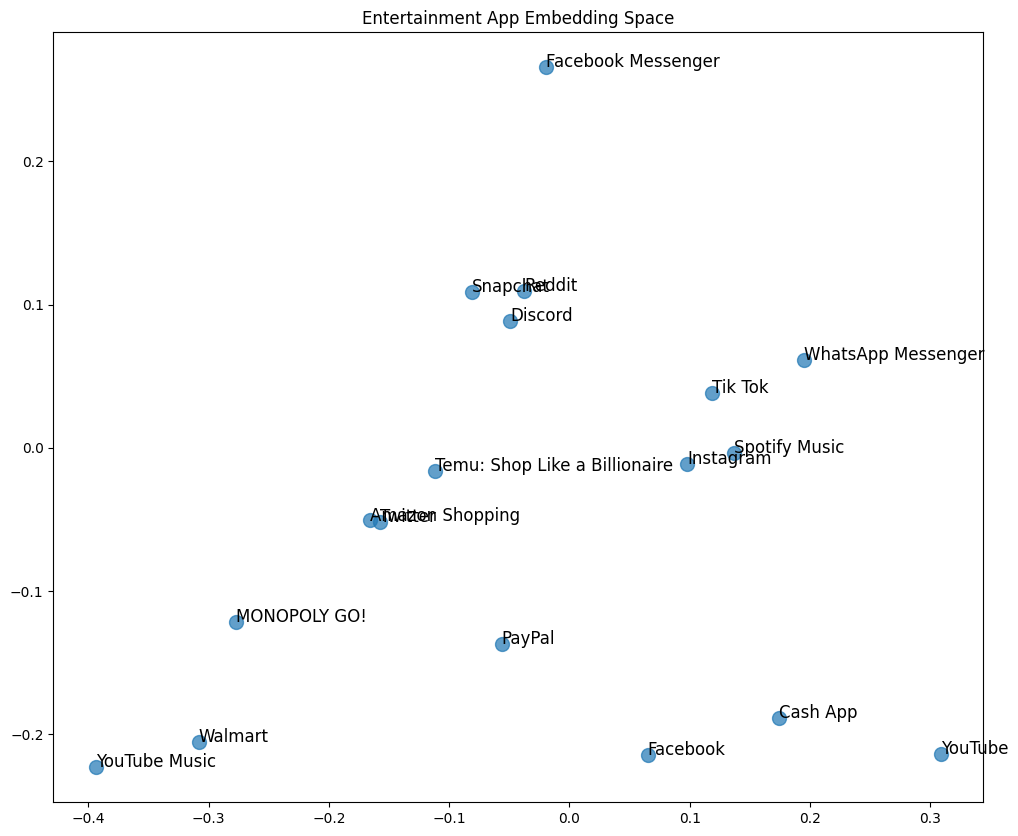

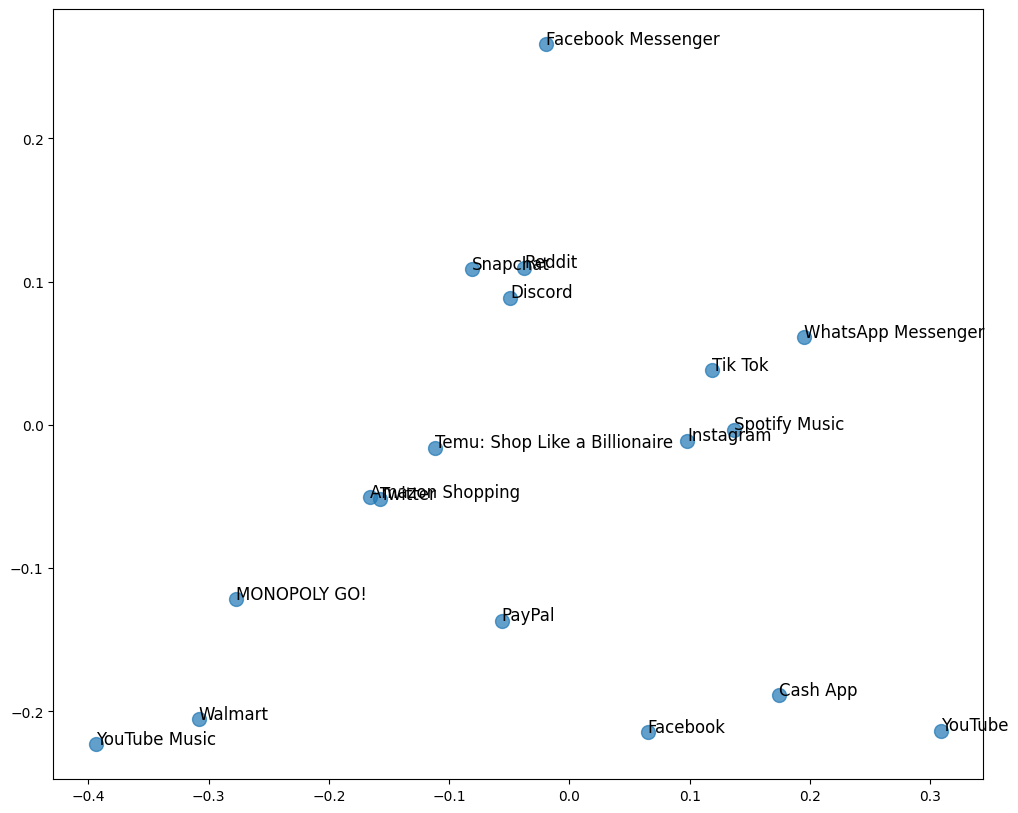

In [43]:
import torch
from torch_geometric.data import HeteroData
from torch_geometric.nn import MetaPath2Vec
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE, MDS
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import matplotlib.cm as cm

# Parameters for MetaPath2Vec (matching the model)
embedding_dim = 64
metapaths = [('app', 'uses', 'user'), ('user', 'uses', 'app')]
walk_length = 50
context_size = 5
walks_per_node = 50
num_negative_samples = 10

# Entertainment apps list
apps = [
    'Tik Tok', 'Instagram', 'YouTube', 'Snapchat', 'Spotify Music', 'YouTube Music', 'Facebook', 'Facebook Messenger',
    'Twitter', 'Reddit', 'Discord', 'WhatsApp Messenger', 'MONOPOLY GO!', 'Amazon Shopping', 'Temu: Shop Like a Billionaire',
    'Walmart', 'PayPal', 'Cash App'
]

# Device setup
device = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')

# Load data and mappings
df_jan_full = pd.read_parquet('jan_aggregated.parquet')
df_feb_full = pd.read_parquet('feb_aggregated.parquet')

user_mapping_jan = {user_id: idx for idx, user_id in enumerate(df_jan_full['PANELISTID'].unique())}
app_mapping_jan = {app_id: idx + len(user_mapping_jan) for idx, app_id in enumerate(df_jan_full['APPDESCRIPTION'].unique())}

# Build January graph (simplified for embedding extraction)
data_jan = HeteroData()
data_jan['user'].num_nodes = len(user_mapping_jan)
data_jan['app'].num_nodes = len(app_mapping_jan)

source_jan = df_jan_full['PANELISTID'].map(user_mapping_jan).values
target_jan = df_jan_full['APPDESCRIPTION'].map(app_mapping_jan).values
edge_index_jan = torch.tensor(np.vstack([source_jan, target_jan]), dtype=torch.long)
edge_index_jan_reverse = torch.tensor(np.vstack([target_jan, source_jan]), dtype=torch.long)

data_jan['user', 'uses', 'app'].edge_index = edge_index_jan
data_jan['app', 'uses', 'user'].edge_index = edge_index_jan_reverse

# Load MetaPath2Vec model and extract embeddings
model = MetaPath2Vec(
    data_jan,
    embedding_dim=embedding_dim,
    metapath=metapaths,
    walk_length=walk_length,
    context_size=context_size,
    walks_per_node=walks_per_node,
    num_negative_samples=num_negative_samples,
    num_nodes_dict={'user': data_jan['user'].num_nodes, 'app': data_jan['app'].num_nodes}
).to(device)

checkpoint = torch.load('metapath2vec_january.pth', map_location=device)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

# Extract app embeddings
app_start_idx = len(user_mapping_jan)
app_embeddings = model.embedding.weight.data[app_start_idx:].cpu().numpy()

# Filter embeddings for the 18 apps
app_indices = {app: app_mapping_jan.get(app) - app_start_idx for app in apps if app in app_mapping_jan}
filtered_indices = [idx for idx in app_indices.values() if idx is not None]
filtered_apps = [app for app, idx in app_indices.items() if idx is not None]
filtered_embeddings = app_embeddings[filtered_indices]

print(f"Filtered {len(filtered_apps)} apps for plotting.")

# Perform KMeans clustering for coloring similar apps
#n_clusters = min(1, len(filtered_embeddings))
#kmeans = KMeans(n_clusters=n_clusters, random_state=42)
#cluster_labels = kmeans.fit_predict(filtered_embeddings)

# Function to plot 2D embeddings with cluster colors, no lines
def plot_2d_embedding(embedding, title, save_path=None):
    plt.figure(figsize=(12, 10))
    #scatter = plt.scatter(embedding[:, 0], embedding[:, 1], c=cluster_labels, cmap=cm.tab10, s=100, alpha=0.7)
    scatter = plt.scatter(embedding[:, 0], embedding[:, 1], s=100, alpha=0.7)
    for i, app in enumerate(filtered_apps):
        plt.text(embedding[i, 0], embedding[i, 1], app, fontsize=12)
    #plt.colorbar(scatter, label='Cluster')
    plt.title(title)
    if save_path:
        plt.savefig(save_path)
    plt.show()


plot_2d_embedding(filtered_embeddings, 'Entertainment App Embedding Space', 'filtered_embeddings.png')
plot_2d_embedding(filtered_embeddings,"")

# PCA
#pca = PCA(n_components=2)
#pca_embedding = pca.fit_transform(filtered_embeddings)
#plot_2d_embedding(pca_embedding, 'PCA 2D Projection of App Embedding Space (Clustered)', 'pca_embedding_clustered.png')

# t-SNE (perplexity tuned for small dataset)
#tsne = TSNE(n_components=2, perplexity=min(5, len(filtered_embeddings)-1), random_state=42)
#tsne_embedding = tsne.fit_transform(filtered_embeddings)
#plot_2d_embedding(tsne_embedding, 't-SNE 2D Projection of App Embedding Space (Clustered)', 'tsne_embedding_clustered.png')

# MDS (using dissimilarity: 1 - cosine similarity)
#norms = np.linalg.norm(filtered_embeddings, axis=1)
#norms[norms == 0] = 1e-10
#cos_sim = np.dot(filtered_embeddings, filtered_embeddings.T) / (norms[:, np.newaxis] * norms)
#dissimilarity = 1 - cos_sim
#mds = MDS(n_components=2, dissimilarity='precomputed', random_state=42)
#mds_embedding = mds.fit_transform(dissimilarity)
#plot_2d_embedding(mds_embedding, 'MDS 2D Projection of App Embedding Space (Clustered)','mds_embedding_clustered.png')

/var/folders/l5/sd0jnm712nvcm2c5_ycg3h8w0000gn/T/ipykernel_38049/2871837966.py:63: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load('metapath2vec_januar

Filtered 18 apps for plotting.
k=2, Silhouette Score: 0.0854
k=3, Silhouette Score: -0.0037
k=4, Silhouette Score: 0.0020
k=5, Silhouette Score: 0.0457
k=6, Silhouette Score: 0.0344
k=7, Silhouette Score: 0.0635
k=8, Silhouette Score: 0.0388
k=9, Silhouette Score: 0.0423
k=10, Silhouette Score: 0.0416
Optimal number of clusters: 2


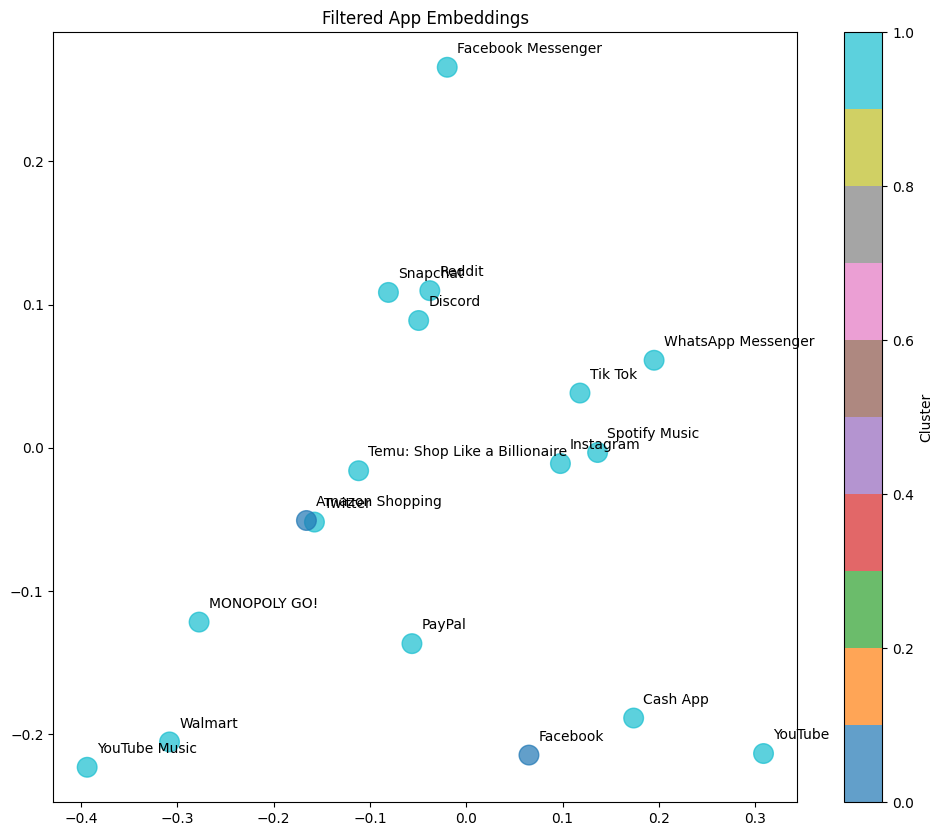

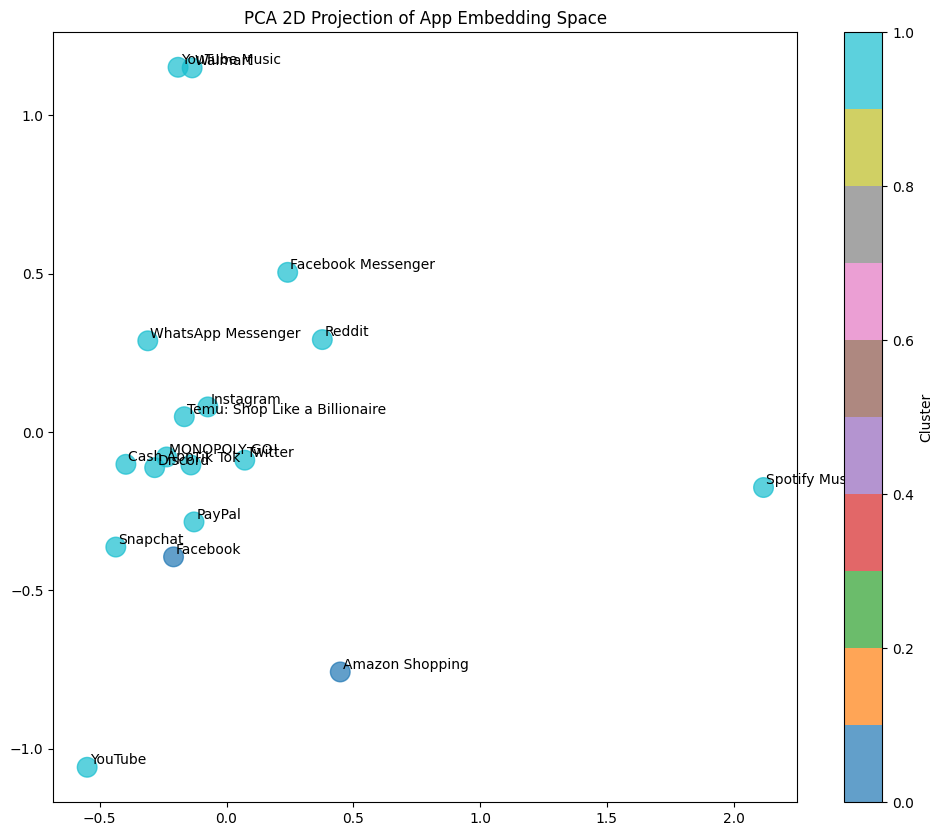

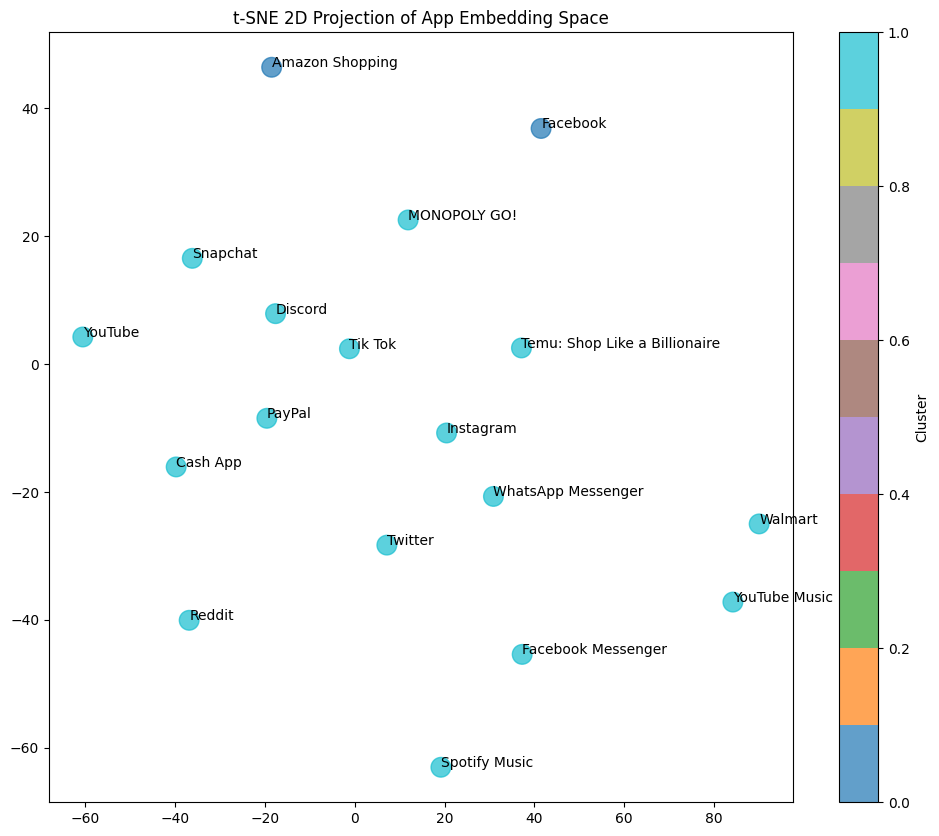

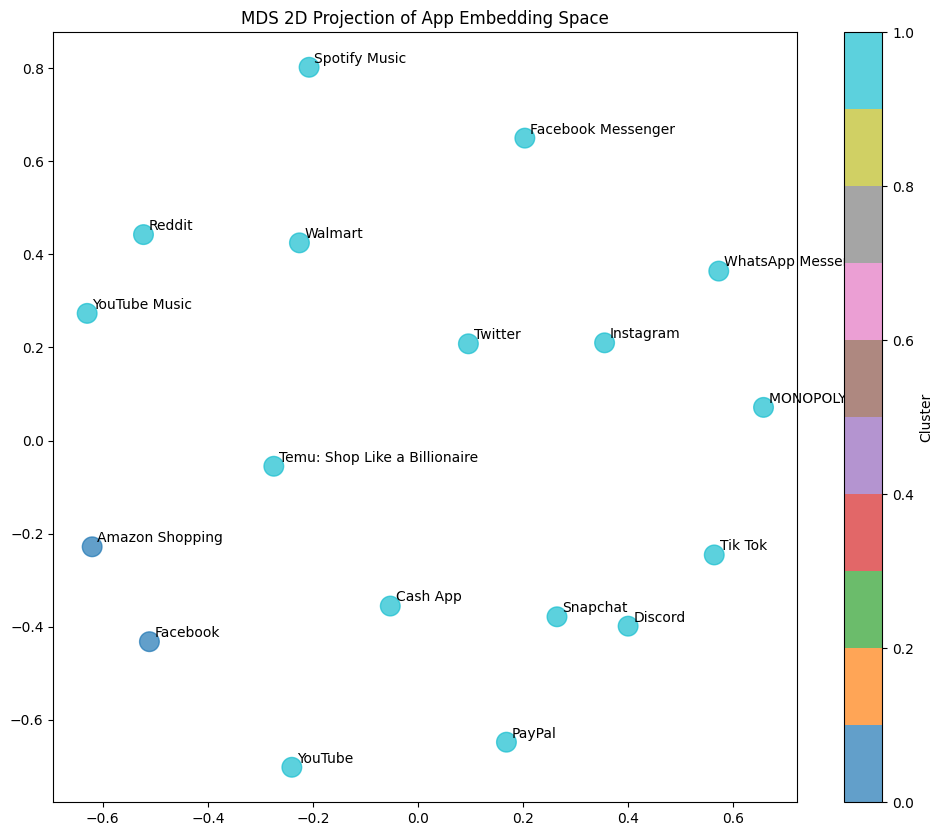

In [13]:
import torch
from torch_geometric.data import HeteroData
from torch_geometric.nn import MetaPath2Vec
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE, MDS
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import matplotlib.cm as cm

# Parameters for MetaPath2Vec (matching the model)
embedding_dim = 64
metapaths = [('app', 'uses', 'user'), ('user', 'uses', 'app')]
walk_length = 50
context_size = 5
walks_per_node = 50
num_negative_samples = 10

# Entertainment apps list
apps = [
    'Tik Tok', 'Instagram', 'YouTube', 'Snapchat', 'Spotify Music', 'YouTube Music', 'Facebook', 'Facebook Messenger',
    'Twitter', 'Reddit', 'Discord', 'WhatsApp Messenger', 'MONOPOLY GO!', 'Amazon Shopping', 'Temu: Shop Like a Billionaire',
    'Walmart', 'PayPal', 'Cash App'
]

# Device setup
device = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')

# Load data and mappings
df_jan_full = pd.read_parquet('jan_aggregated.parquet')
df_feb_full = pd.read_parquet('feb_aggregated.parquet')

user_mapping_jan = {user_id: idx for idx, user_id in enumerate(df_jan_full['PANELISTID'].unique())}
app_mapping_jan = {app_id: idx + len(user_mapping_jan) for idx, app_id in enumerate(df_jan_full['APPDESCRIPTION'].unique())}

# Build January graph (simplified for embedding extraction)
data_jan = HeteroData()
data_jan['user'].num_nodes = len(user_mapping_jan)
data_jan['app'].num_nodes = len(app_mapping_jan)

source_jan = df_jan_full['PANELISTID'].map(user_mapping_jan).values
target_jan = df_jan_full['APPDESCRIPTION'].map(app_mapping_jan).values
edge_index_jan = torch.tensor(np.vstack([source_jan, target_jan]), dtype=torch.long)
edge_index_jan_reverse = torch.tensor(np.vstack([target_jan, source_jan]), dtype=torch.long)

data_jan['user', 'uses', 'app'].edge_index = edge_index_jan
data_jan['app', 'uses', 'user'].edge_index = edge_index_jan_reverse

# Load MetaPath2Vec model and extract embeddings
model = MetaPath2Vec(
    data_jan,
    embedding_dim=embedding_dim,
    metapath=metapaths,
    walk_length=walk_length,
    context_size=context_size,
    walks_per_node=walks_per_node,
    num_negative_samples=num_negative_samples,
    num_nodes_dict={'user': data_jan['user'].num_nodes, 'app': data_jan['app'].num_nodes}
).to(device)

checkpoint = torch.load('metapath2vec_january.pth', map_location=device)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

# Extract app embeddings
app_start_idx = len(user_mapping_jan)
app_embeddings = model.embedding.weight.data[app_start_idx:].cpu().numpy()

# Filter embeddings for the 18 apps
app_indices = {app: app_mapping_jan.get(app) - app_start_idx for app in apps if app in app_mapping_jan}
filtered_indices = [idx for idx in app_indices.values() if idx is not None]
filtered_apps = [app for app, idx in app_indices.items() if idx is not None]
filtered_embeddings = app_embeddings[filtered_indices]

print(f"Filtered {len(filtered_apps)} apps for plotting.")

# Automatically determine optimal number of clusters using silhouette score
silhouette_scores = []
max_k = min(10, len(filtered_embeddings) - 1)
for k in range(2, max_k + 1):
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(filtered_embeddings)
    score = silhouette_score(filtered_embeddings, labels)
    silhouette_scores.append(score)
    print(f"k={k}, Silhouette Score: {score:.4f}")

optimal_k = np.argmax(silhouette_scores) + 2  # +2 because range starts from 2
print(f"Optimal number of clusters: {optimal_k}")

# Perform KMeans clustering with optimal k
kmeans = KMeans(n_clusters=optimal_k, random_state=42)
cluster_labels = kmeans.fit_predict(filtered_embeddings)

# Function to plot 2D embeddings with cluster colors, no lines
def plot_2d_embedding(embedding, title, save_path=None):
    plt.figure(figsize=(12, 10))
    scatter = plt.scatter(embedding[:, 0], embedding[:, 1], c=cluster_labels, cmap=cm.tab10, s=200, alpha=0.7)
    for i, app in enumerate(filtered_apps):
        plt.text(embedding[i, 0] + 0.01, embedding[i, 1] + 0.01, app, fontsize=10)
    plt.colorbar(scatter, label='Cluster')
    plt.title(title)
    if save_path:
        plt.savefig(save_path)
    plt.show()

plot_2d_embedding(filtered_embeddings, 'Filtered App Embeddings', 'filtered_embeddings.png')

# PCA
pca = PCA(n_components=2)
pca_embedding = pca.fit_transform(filtered_embeddings)
plot_2d_embedding(pca_embedding, 'PCA 2D Projection of App Embedding Space', 'pca_embedding_clustered.png')

# t-SNE (perplexity tuned for small dataset)
tsne = TSNE(n_components=2, perplexity=min(5, len(filtered_embeddings)-1), random_state=42)
tsne_embedding = tsne.fit_transform(filtered_embeddings)
plot_2d_embedding(tsne_embedding, 't-SNE 2D Projection of App Embedding Space', 'tsne_embedding_clustered.png')

# MDS (using dissimilarity: 1 - cosine similarity)
norms = np.linalg.norm(filtered_embeddings, axis=1)
norms[norms == 0] = 1e-10
cos_sim = np.dot(filtered_embeddings, filtered_embeddings.T) / (norms[:, np.newaxis] * norms)
dissimilarity = 1 - cos_sim
mds = MDS(n_components=2, dissimilarity='precomputed', random_state=42)
mds_embedding = mds.fit_transform(dissimilarity)
plot_2d_embedding(mds_embedding, 'MDS 2D Projection of App Embedding Space', 'mds_embedding_clustered.png')

/var/folders/l5/sd0jnm712nvcm2c5_ycg3h8w0000gn/T/ipykernel_34147/1965086281.py:58: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load('metapath2vec_januar

Plotting for 74754 apps.
Too many apps; skipping labels for clarity.


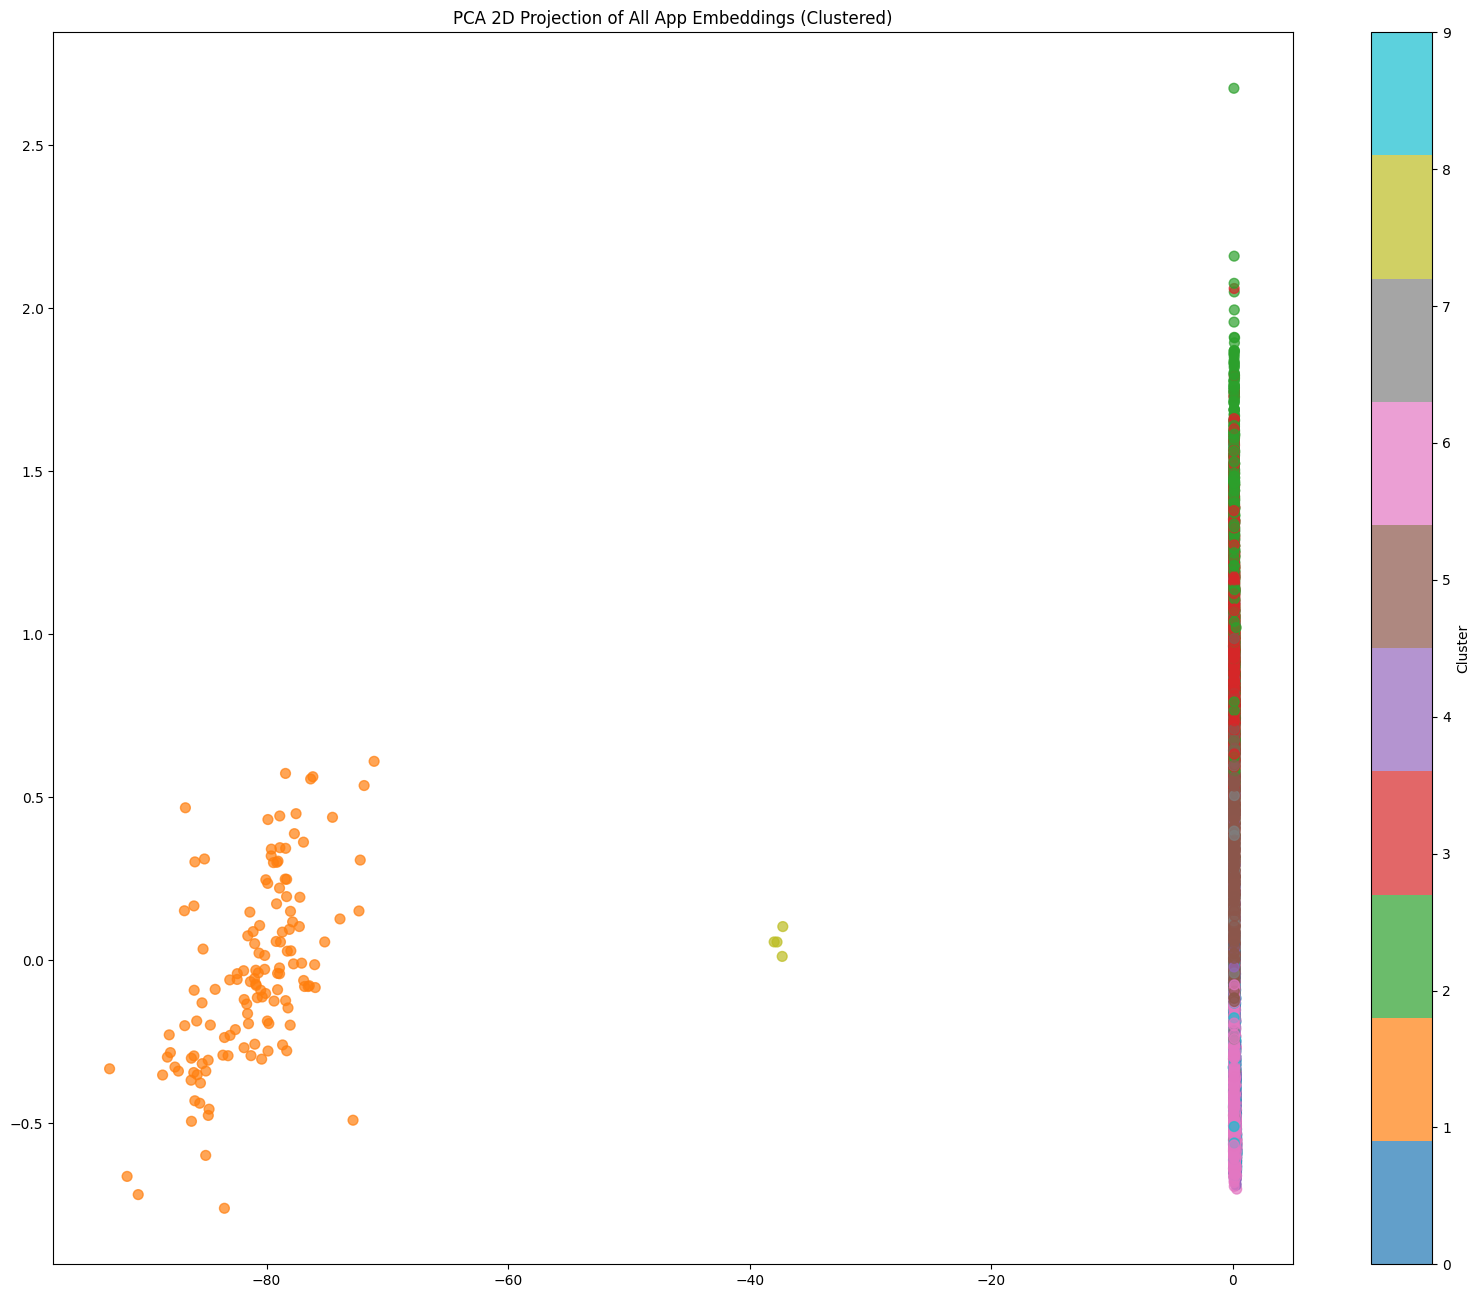

Too many apps; skipping labels for clarity.


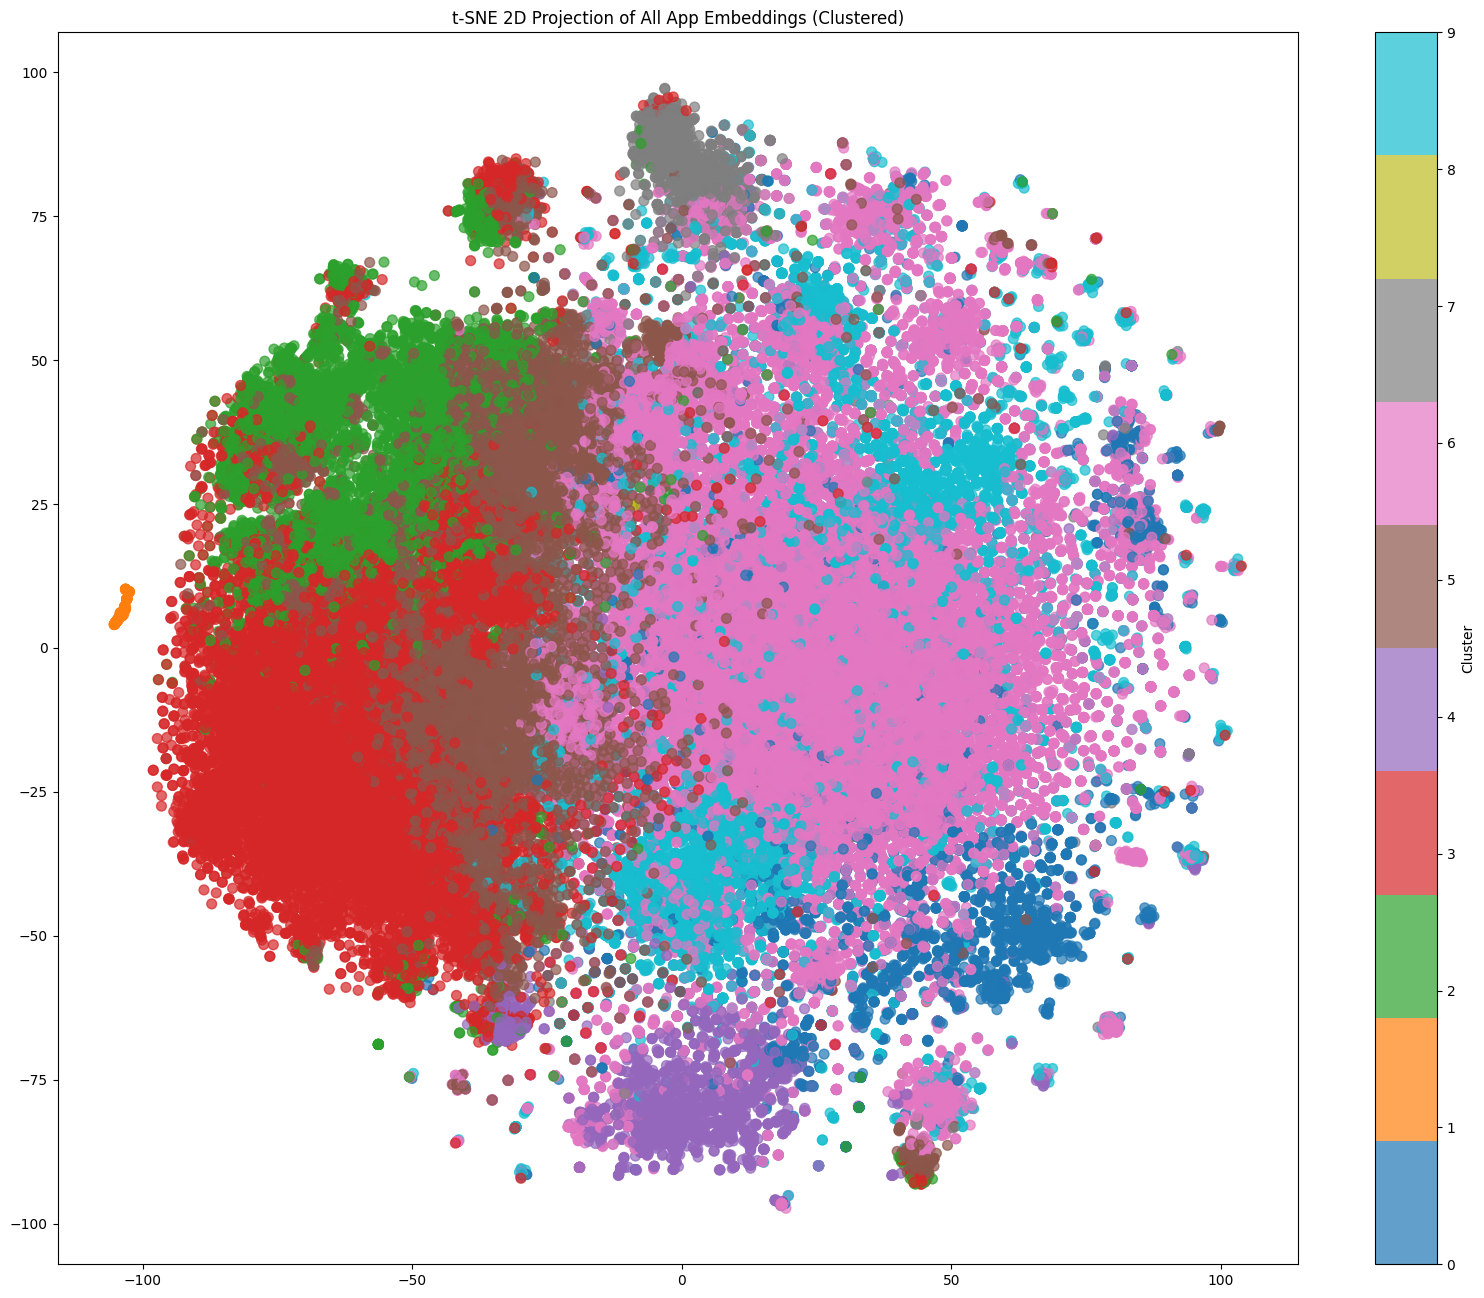

: 

In [5]:
import torch
from torch_geometric.data import HeteroData
from torch_geometric.nn import MetaPath2Vec
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE, MDS
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import matplotlib.cm as cm

# Parameters for MetaPath2Vec (matching the model)
embedding_dim = 64
metapaths = [('app', 'uses', 'user'), ('user', 'uses', 'app')]
walk_length = 50
context_size = 5
walks_per_node = 50
num_negative_samples = 10

# Device setup
device = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')

# Load data and mappings
df_jan_full = pd.read_parquet('jan_aggregated.parquet')
df_feb_full = pd.read_parquet('feb_aggregated.parquet')

# Get all unique apps
apps = sorted(df_jan_full['APPDESCRIPTION'].unique())

user_mapping_jan = {user_id: idx for idx, user_id in enumerate(df_jan_full['PANELISTID'].unique())}
app_mapping_jan = {app_id: idx + len(user_mapping_jan) for idx, app_id in enumerate(apps)}

# Build January graph (simplified for embedding extraction)
data_jan = HeteroData()
data_jan['user'].num_nodes = len(user_mapping_jan)
data_jan['app'].num_nodes = len(app_mapping_jan)

source_jan = df_jan_full['PANELISTID'].map(user_mapping_jan).values
target_jan = df_jan_full['APPDESCRIPTION'].map(app_mapping_jan).values
edge_index_jan = torch.tensor(np.vstack([source_jan, target_jan]), dtype=torch.long)
edge_index_jan_reverse = torch.tensor(np.vstack([target_jan, source_jan]), dtype=torch.long)

data_jan['user', 'uses', 'app'].edge_index = edge_index_jan
data_jan['app', 'uses', 'user'].edge_index = edge_index_jan_reverse

# Load MetaPath2Vec model and extract embeddings
model = MetaPath2Vec(
    data_jan,
    embedding_dim=embedding_dim,
    metapath=metapaths,
    walk_length=walk_length,
    context_size=context_size,
    walks_per_node=walks_per_node,
    num_negative_samples=num_negative_samples,
    num_nodes_dict={'user': data_jan['user'].num_nodes, 'app': data_jan['app'].num_nodes}
).to(device)

checkpoint = torch.load('metapath2vec_january.pth', map_location=device)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

# Extract app embeddings
app_start_idx = len(user_mapping_jan)
app_embeddings = model.embedding.weight.data[app_start_idx:].cpu().numpy()

# Use all apps
filtered_apps = apps
filtered_embeddings = app_embeddings

print(f"Plotting for {len(filtered_apps)} apps.")

# Perform KMeans clustering for coloring similar apps
n_clusters = min(10, len(filtered_embeddings))  # Adjust as needed, e.g., 10 clusters
kmeans = KMeans(n_clusters=n_clusters, random_state=42)
cluster_labels = kmeans.fit_predict(filtered_embeddings)

# Function to plot 2D embeddings with cluster colors, no lines
def plot_2d_embedding(embedding, title, save_path=None):
    plt.figure(figsize=(20, 16))
    scatter = plt.scatter(embedding[:, 0], embedding[:, 1], c=cluster_labels, cmap=cm.tab10, s=50, alpha=0.7)
    # Skip labels if too many apps
    if len(filtered_apps) <= 50:
        for i, app in enumerate(filtered_apps):
            plt.text(embedding[i, 0] + 0.01, embedding[i, 1] + 0.01, app, fontsize=8)
    else:
        print("Too many apps; skipping labels for clarity.")
    plt.colorbar(scatter, label='Cluster')
    plt.title(title)
    if save_path:
        plt.savefig(save_path)
    plt.show()

# PCA
pca = PCA(n_components=2)
pca_embedding = pca.fit_transform(filtered_embeddings)
plot_2d_embedding(pca_embedding, 'PCA 2D Projection of All App Embeddings (Clustered)', 'pca_all_apps_clustered.png')

# t-SNE (perplexity tuned)
perplexity = min(30, len(filtered_embeddings) - 1)
tsne = TSNE(n_components=2, perplexity=perplexity, random_state=42)
tsne_embedding = tsne.fit_transform(filtered_embeddings)
plot_2d_embedding(tsne_embedding, 't-SNE 2D Projection of All App Embeddings (Clustered)', 'tsne_all_apps_clustered.png')

# MDS (using dissimilarity: 1 - cosine similarity)
norms = np.linalg.norm(filtered_embeddings, axis=1)
norms[norms == 0] = 1e-10
cos_sim = np.dot(filtered_embeddings, filtered_embeddings.T) / (norms[:, np.newaxis] * norms)
dissimilarity = 1 - cos_sim
mds = MDS(n_components=2, dissimilarity='precomputed', random_state=42)
mds_embedding = mds.fit_transform(dissimilarity)
plot_2d_embedding(mds_embedding, 'MDS 2D Projection of All App Embeddings (Clustered)', 'mds_all_apps_clustered.png')